<a href="https://colab.research.google.com/github/RafaelSinhorini/An-lise_Precos_Im-veis_SP/blob/main/PRECO_IMOVEIS_SP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Predição de Preços de Imóveis utilizando Machine Learning**

##Projeto Integrador – Ciência de Dados - UNIVESP 2026



##***1. Introdução***
Este projeto tem como objetivo desenvolver um modelo de Machine Learning capaz de estimar o preço de imóveis na cidade de São Paulo, utilizando características presentes em uma base de dados brasileira de imóveis.

Serão analisadas variáveis relacionadas às características dos imóveis, como área, quantidade de quartos, banheiros, vagas de garagem, localização e outras informações disponíveis na base de dados.

O projeto será desenvolvido utilizando a linguagem Python e executado no ambiente Google Colab. Ao longo do desenvolvimento serão realizadas etapas de carregamento e compreensão dos dados, tratamento, análise exploratória, preparação das variáveis, treinamento de modelos de Machine Learning e avaliação dos resultados

##***2. Importação das Bibliotecas***


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Configurando a visualização de dados numéricos no Pandas para o padrão brasileiro (000.000,00)

In [ ]:
pd.set_option(
    'display.float_format',
    lambda x: f'{x:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.')
)

##***3. Importação dos Dados***
Base de dados obtida na seguinte URL https://www.kaggle.com/datasets/rogerio/image-based-property-price-prediction-in-so-paulo?utm_source=chatgpt.com&select=Imagens


In [ ]:
!ls "/content/drive/MyDrive/Colab Notebooks/PROJETO IV- UNIVESP/"

data_preco_sp.csv  PRECO_IMOVEIS_SP.html  PRECO_IMOVEIS_SP.ipynb


In [ ]:
import pandas as pd

df = pd.read_csv(
    '/content/drive/MyDrive/Colab Notebooks/PROJETO IV- UNIVESP/data_preco_sp.csv',
    sep=';'
)

## ***4. Primeiras análises exploratórias da base de dados***

In [ ]:
df.head()


,index,title,price,oldPrice,location,date,destaque,Categoria,Tipo,Condomínio,...,Área de serviço,Armários na cozinha,Armários no quarto,Churrasqueira,Mobiliado,Quarto de serviço,Ar condicionado,Porteiro 24h,Varanda,bairro
0,0,Apartamento Reserva Raposo,299000,NaN,"São Paulo, Jardim Boa Vista (Zona Oeste)",25/04/2024,True,Apartamentos,Padrão,"450,00",...,1,1,0,0,0,0,0,0,0,Jardim Boa Vista
1,1,Apartamento MOBILIADO com ÓTIMA Localização Ág...,350000,NaN,"São Paulo, Água Branca",25/04/2024,True,Apartamentos,Padrão,"380,00",...,1,1,1,1,1,0,0,0,0,Água Branca
2,2,"Apartamento 115.000,00",115000,NaN,"São Paulo, Parque Nações Unidas",24/04/2024,True,Apartamentos,Padrão,"150,00",...,1,1,0,0,0,0,0,0,0,Parque Nações Unidas
3,3,"Apartamento 3 dorm + 1 HomeOffice, Pirituba, c...",240000,"280.000,00","São Paulo, Vila Guedes",24/04/2024,True,Apartamentos,Padrão,"400,00",...,1,1,1,0,1,1,0,0,0,Vila Guedes
4,4,Casa de condomínio sobrado para venda com 97 m...,570000,NaN,"São Paulo, Jardim Sarah",25/04/2024,False,Casas,Casa de condomínio,"320,00",...,1,1,1,0,0,0,1,1,0,Jardim Sarah


In [ ]:
df.shape

(23433, 38)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23433 entries, 0 to 23432
Data columns (total 38 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   index                   23433 non-null  int64  
 1   title                   23433 non-null  object 
 2   price                   23433 non-null  int64  
 3   oldPrice                890 non-null    float64
 4   location                23433 non-null  object 
 5   date                    23433 non-null  object 
 6   destaque                23433 non-null  bool   
 7   Categoria               23433 non-null  object 
 8   Tipo                    23433 non-null  object 
 9   Condomínio              23266 non-null  float64
 10  Área útil               23433 non-null  int64  
 11  Quartos                 23433 non-null  object 
 12  Banheiros               23427 non-null  object 
 13  Vagas na garagem        23433 non-null  object 
 14  Detalhes do imóvel      16298 non-null

##***5. Conhecimento e caracterização dos dados***

> Adicionar aspas



A partir das primeiras análises, já é possível entender que a base de dados utilizada neste projeto é composta por 23.433 registros de imóveis  anunciados na cidade de São Paulo, contendo 38 variáveis relacionadas às características dos imóveis, localização, valores e infraestrutura.

*Principais variáveis disponíveis:

*   preço
*   quantidade de quartos
*   área útil
*   banheiros
*   vagas de garagem
*   valor do condomínio
*   IPTU
*   zona da cidade
*   bairro
*   características adicionais: (elevador, piscina, academia, varanda e mobiliário)

A variável ***price*** representa o preço anunciado do imóvel e será utilizada como **variável-alvo (target)** no desenvolvimento dos modelos de Machine Learning. Como o objetivo é prever um valor numérico contínuo, o problema será tratado como uma tarefa de regressão supervisionada.



###5.1. Qualidade e estrutura dos dados

A análise inicial da estrutura dos dados também identificou diferentes tipos de variáveis e a presença de valores ausentes em algumas colunas. Além disso, algumas variáveis que representam quantidades, como quartos, banheiros e vagas de garagem, foram inicialmente interpretadas pelo Pandas como dados do tipo object, sendo necessária uma análise posterior para verificar sua estrutura e realizar eventual conversão para formatos numéricos.

Essas características serão consideradas nas etapas seguintes de preparação e tratamento dos dados, evitando alterações prematuras que possam comprometer a análise.

###5.2. Análise da ***Variável-Alvo (price)***

####5.2.1. Análise estatística da variável-alvo
Análise específica da variável ***price*** que será utilizada como target no modelo de predição que será trabalhado, portanto se faz necessário entender as características estatísticas dessa variável

In [ ]:
df['price'].describe()

,price
count,"23.433,00"
mean,"1.381.088,43"
std,"1.771.253,89"
min,"0,00"
25%,"518.000,00"
50%,"920.000,00"
75%,"1.649.970,00"
max,"45.900.000,00"


####5.2.2. Identificação de valores extremos na variável-alvo
A análise estatística  identificou uma diferença significativa entre a média e a mediana dos preços, além da presença de valores mínimos iguais a zero e valores máximos elevados. Esses resultados indicam a necessidade de investigar possíveis valores extremos e inconsistências na variável-alvo antes da etapa de modelagem.


In [ ]:
(df['price'] == 0).sum()

np.int64(1)

Apenas uma linha da coluna PRICE está com valor zero, portanto vamos considerá-la como OUTLIER
Investigando qual é o registro que apresenta o valor 0 nessa coluna.


In [ ]:
df[df['price'] == 0]

,index,title,price,oldPrice,location,date,destaque,Categoria,Tipo,Condomínio,...,Área de serviço,Armários na cozinha,Armários no quarto,Churrasqueira,Mobiliado,Quarto de serviço,Ar condicionado,Porteiro 24h,Varanda,bairro
789,789,Sócio investidor. Pizza/bar vila Madalena Rua ...,0,NaN,"São Paulo, Vila Madalena",25/04/2024,False,Casas,Padrão,"12.000,00",...,0,0,0,0,1,0,0,0,0,Vila Madalena


####5.2.3. Análise Gráfica variável Alvo

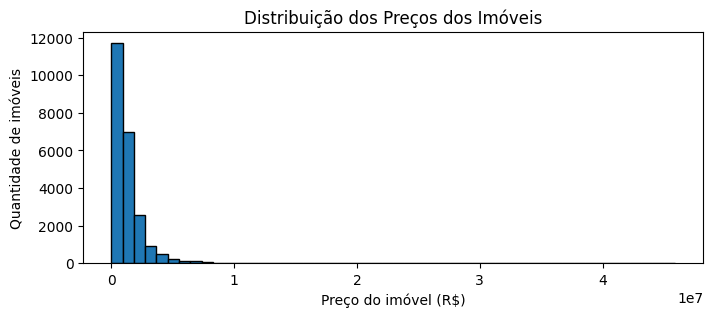

In [ ]:
# Histograma da variável preço
plt.figure(figsize=(8, 3))

plt.hist(df['price'], bins=50, edgecolor='black')

plt.title('Distribuição dos Preços dos Imóveis')
plt.xlabel('Preço do imóvel (R$)')
plt.ylabel('Quantidade de imóveis')

plt.show()

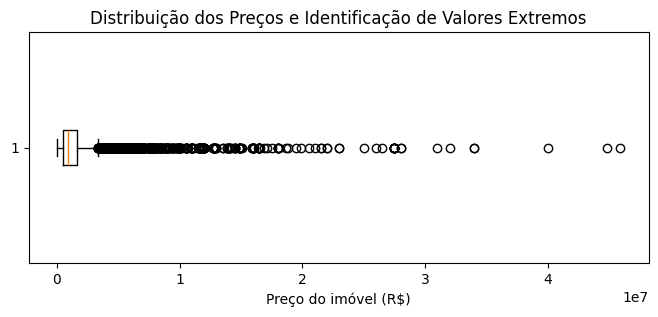

In [ ]:
# Boxplot da variável preço
plt.figure(figsize=(8, 3))

plt.boxplot(df['price'], vert=False)

plt.title('Distribuição dos Preços e Identificação de Valores Extremos')
plt.xlabel('Preço do imóvel (R$)')

plt.show()

####5.2.4.Conclusões sobre a variável-alvo (price)
A variável ***price***, definida como alvo do modelo de predição, apresenta grande variação entre os valores registrados. A diferença entre média e mediana, somada à assimetria observada nos gráficos, demonstra maior concentração de imóveis nas faixas de menor preço e presença de diversos valores extremos. Também foi identificado um registro com preço igual a zero, considerado inconsistente. Entretanto, os valores elevados não devem ser classificados automaticamente como erros, pois podem representar imóveis de alto padrão. Essas características deverão ser consideradas na etapa de tratamento e na escolha das estratégias de preparação da variável para o modelo de Machine Learning.

###5.3. Análises da variável ***quarto***
####5.3.1. Análise dos valores, para entender o tipo de classificação "object"

In [ ]:
df['Quartos'].value_counts()

,count
Quartos,
3,9849
2,7599
4,2927
1,2581
5 ou mais,453
0,24


A partir da análise do conteúdo na variável quarto, é possível perceber que existe a informação "5 ou mais" por isso ela está sendo tratada como object, também temos a existência de 24 registros com valor = 0


####5.3.2 Análise Gráfica da variável quarto

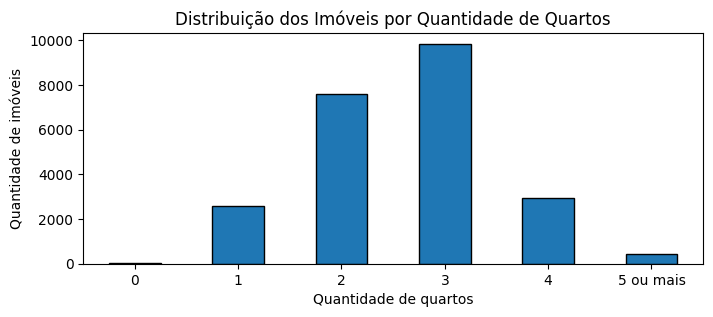

In [ ]:
# Gráfico de distribuição da quantidade de quartos
ordem_quartos = ['0', '1', '2', '3', '4', '5 ou mais']

contagem_quartos = (
    df['Quartos']
    .astype(str)
    .value_counts()
    .reindex(ordem_quartos, fill_value=0)
)

plt.figure(figsize=(8, 3))

contagem_quartos.plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Distribuição dos Imóveis por Quantidade de Quartos')
plt.xlabel('Quantidade de quartos')
plt.ylabel('Quantidade de imóveis')
plt.xticks(rotation=0)

plt.show()

####5.3.3. Conclusões sobre a variável Quartos
A variável Quartos apresenta maior concentração de imóveis com dois ou três quartos, sendo a categoria de três quartos a mais frequente. A presença da categoria textual “5 ou mais” explica sua classificação atual como object e indica a necessidade de conversão para formato numérico na etapa de tratamento. Também foram identificados 24 imóveis com zero quartos, que deverão ser investigados, pois podem representar imóveis sem divisão convencional, como lofts e kitnets, ou possíveis inconsistências de preenchimento. De modo geral, a variável demonstra potencial relevância para o futuro modelo de predição de preços.

###5.4. Análise da variável ***Banheiro***

####5.4.1. Identificação da variável banheiro
Análise dos valores, para entender o tipo de classificação "object"

In [ ]:
df['Banheiros'].value_counts()

,count
Banheiros,
2,6884
1,6654
3,4497
4,2788
5 ou mais,2604


Assim como na variável quarto, alguns lançamentos também possuem o valor "5 ou mais", explicando o porque da variável estar classificada como object

###5.4.2. Análise Gráfica da Variável Banheiro

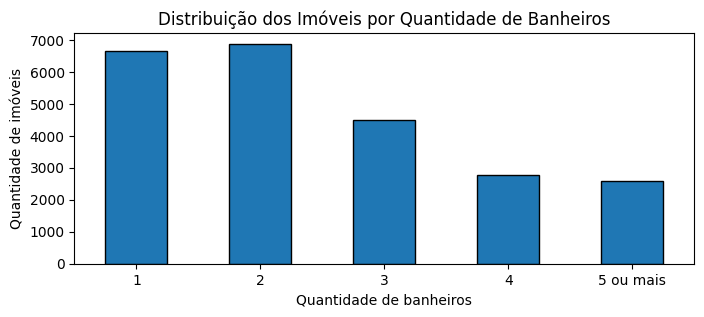

In [ ]:
# Gráfico de distribuição da quantidade de banheiros
ordem_banheiros = ['1', '2', '3', '4', '5 ou mais']

contagem_banheiros = (
    df['Banheiros']
    .astype(str)
    .value_counts()
    .reindex(ordem_banheiros, fill_value=0)
)

plt.figure(figsize=(8, 3))

contagem_banheiros.plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Distribuição dos Imóveis por Quantidade de Banheiros')
plt.xlabel('Quantidade de banheiros')
plt.ylabel('Quantidade de imóveis')
plt.xticks(rotation=0)

plt.show()

####5.4.3 Conclusões sobre a variável banheiro
A variável Banheiros apresenta maior concentração de imóveis com um ou dois banheiros, enquanto as demais categorias possuem frequências progressivamente menores. A presença da categoria textual “5 ou mais” explica sua classificação como object e exigirá conversão para formato numérico na etapa de tratamento. Também foram identificados seis valores ausentes, que deverão ser tratados posteriormente. De modo geral, essa variável apresenta boa distribuição e potencial relevância para o futuro modelo de predição de preços.

###5.5. Análise da Variável ***Vagas na garagem***


####5.5.1. Identificação da variável Vagas na garagem

In [ ]:
df['Vagas na garagem'].value_counts()

,count
Vagas na garagem,
1,8117
2,7196
0,2967
3,2480
4,1548
5 ou mais,1125


####5.5.2. Análise Gráfica variável Vagas na garagem

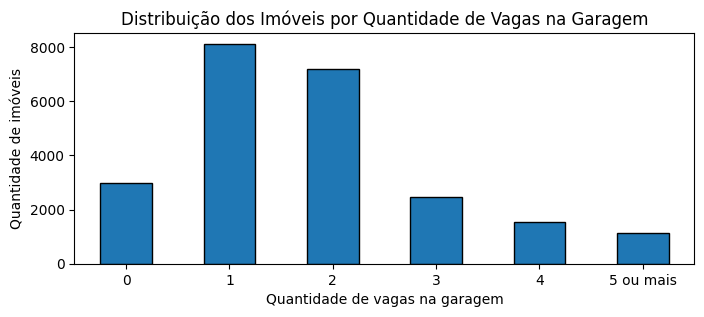

In [ ]:
# Gráfico de distribuição da quantidade de vagas na garagem
ordem_vagas = ['0', '1', '2', '3', '4', '5 ou mais']

contagem_vagas = (
    df['Vagas na garagem']
    .astype(str)
    .value_counts()
    .reindex(ordem_vagas, fill_value=0)
)

plt.figure(figsize=(8, 3))

contagem_vagas.plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Distribuição dos Imóveis por Quantidade de Vagas na Garagem')
plt.xlabel('Quantidade de vagas na garagem')
plt.ylabel('Quantidade de imóveis')
plt.xticks(rotation=0)

plt.show()

####5.5.3 Conclusões sobre a variável Vagas na garagem
A variável Vagas na garagem apresenta maior concentração de imóveis com uma ou duas vagas, enquanto imóveis com três ou mais vagas possuem menor frequência. Também existe uma quantidade relevante de imóveis sem vaga de garagem, o que pode representar uma característica legítima, especialmente em determinadas categorias ou localizações. A presença da categoria textual“5 ou mais” explica sua classificação como object e exigirá conversão para formato numérico na etapa de tratamento. De modo geral, a variável demonstra potencial relevância para o futuro modelo de predição de preços.

###5.6. Análise da variável ***OldPrice***

####5.6.1. Identificação da variável oldPrice

In [ ]:
df['oldPrice'].describe()

,oldPrice
count,"890,00"
mean,"1.219.728,52"
std,"3.187.313,14"
min,"85.000,00"
25%,"364.545,00"
50%,"782.395,00"
75%,"1.499.989,75"
max,"90.000.000,00"


A coluna ***oldPrice*** possui uma grande quantidade de valores ausentes, o que indica que esta pode ser uma variável a ser descartada futuramente.

####5.6.2 Conclusões sobre a variável oldPrice
A variável oldPrice apresenta aproximadamente 96,20% de valores ausentes, estando disponível para uma parcela muito pequena dos imóveis. Essa baixa disponibilidade compromete sua representatividade e utilidade para o futuro modelo de predição. Portanto, a variável é considerada uma forte candidata à exclusão na etapa de tratamento dos dados, não sendo necessária a realização de análises gráficas adicionais.

###5.7. Análise da variável ***Condomínio***

####5.7.1. Identificação da variável Condomínio

In [ ]:
df['Condomínio'].describe()

,Condomínio
count,"23.266,00"
mean,"2.309,32"
std,"83.410,02"
min,"0,00"
25%,"1,00"
50%,"750,00"
75%,"1.500,00"
max,"11.800.000,00"


Os valores encontrados na coluna ***condomínio*** podem representar a presença de um outlier, com um valor máximo de R$11.800.000,00 e uma grande diferença entre Média e Mediana.
O próximo passo será investigar qual é exatamente esse imóvel com o valor de condomínio tão alto.

In [ ]:
df[df['Condomínio'] == df['Condomínio'].max()]

,index,title,price,oldPrice,location,date,destaque,Categoria,Tipo,Condomínio,...,Área de serviço,Armários na cozinha,Armários no quarto,Churrasqueira,Mobiliado,Quarto de serviço,Ar condicionado,Porteiro 24h,Varanda,bairro
13290,13290,Cobertura triplex para aluguel e venda com 118...,18000000,NaN,"São Paulo, Santa Cecília",22/04/2024,False,Apartamentos,Cobertura,"11.800.000,00",...,0,0,0,1,1,0,1,0,1,Santa Cecília


Analisando a linha de índice 13290, encontramos o registro que possui inconsistência na coluna valor do condomínio, por tratar-se de um valor irreal, quase igual ao valor do próprio imóvel, consideraremos que esse será um dado inválido.

###5.7.2. Análise gráfica da variável condomínio

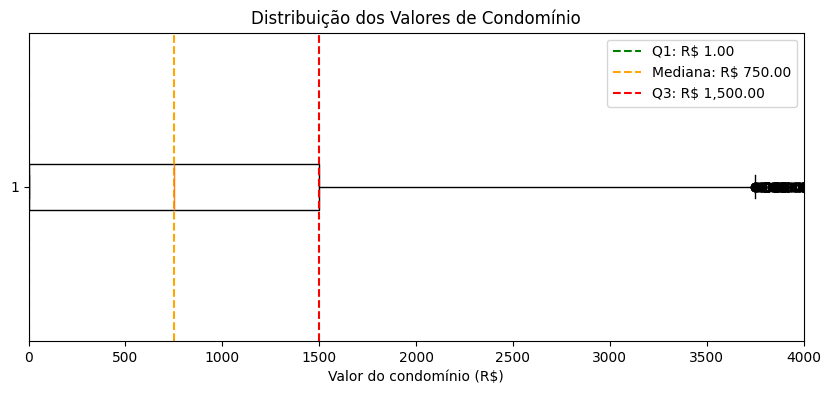

In [ ]:
# Cálculo dos quartis
condominio = df['Condomínio'].dropna()

q1 = condominio.quantile(0.25)
mediana = condominio.quantile(0.50)
q3 = condominio.quantile(0.75)

# Boxplot com destaque para os quartis
plt.figure(figsize=(10, 4))

plt.boxplot(condominio, vert=False)

plt.xlim(0, 4000)

plt.axvline(q1, color='green', linestyle='--', label=f'Q1: R$ {q1:,.2f}')
plt.axvline(mediana, color='orange', linestyle='--', label=f'Mediana: R$ {mediana:,.2f}')
plt.axvline(q3, color='red', linestyle='--', label=f'Q3: R$ {q3:,.2f}')

plt.title('Distribuição dos Valores de Condomínio')
plt.xlabel('Valor do condomínio (R$)')
plt.legend()

plt.show()

####5.7.3. Conclusões sobre a variável Condomínio
A variável Condomínio apresenta forte assimetria e diversos valores extremos. Os quartis indicam que 25% dos registros possuem valores de até R$ 1,00, sugerindo possíveis valores simbólicos ou erros de preenchimento, enquanto a mediana é de  750,00 e 75% dos registros apresentam valores de até 1.500,00. Também foi identificado um valor máximo de 11.800.000,00, considerado inconsistente após a análise do respectivo imóvel. Portanto, essa variável possui potencial relevância para a predição dos preços, mas exigirá investigação e tratamento dos valores inconsistentes antes da modelagem.

###5.8. Análise da variável ***IPTU***

####5.8.1. Identificação da variável IPTU

In [ ]:
df['IPTU'].describe()

,IPTU
count,"23.232,00"
mean,"1.789,94"
std,"90.517,09"
min,"0,00"
25%,"1,00"
50%,"178,00"
75%,"570,00"
max,"9.751.020,00"


Novamente verificamos um potencial outlier na variável IPTU, com um valor que apresenta o valor R$ 9.751.020,00
O próximo passo será identificar qual é esse registro, e analisar se o valor de IPTU pode ser considerado real

In [ ]:
df[df['IPTU'] == df['IPTU'].max()]

,index,title,price,oldPrice,location,date,destaque,Categoria,Tipo,Condomínio,...,Área de serviço,Armários na cozinha,Armários no quarto,Churrasqueira,Mobiliado,Quarto de serviço,Ar condicionado,Porteiro 24h,Varanda,bairro
18297,18297,Cobertura em Rua Franco Paulista - Santana - S...,1299710,NaN,"São Paulo, Água Fria",22/04/2024,False,Apartamentos,Cobertura,"2.800.000,00",...,0,0,0,0,0,0,0,0,0,Água Fria


Analisando especificamente o registro em questão, encontramos novamente uma discrepância dessa vez comparando o valor do imóvel com o preço do IPTU, que está quase 7,5 vezes maior, o que indica um provável erro de digitação e a necessidade futura de excluir esse dado.

####5.8.2 Análise Gráfica da variável IPTU

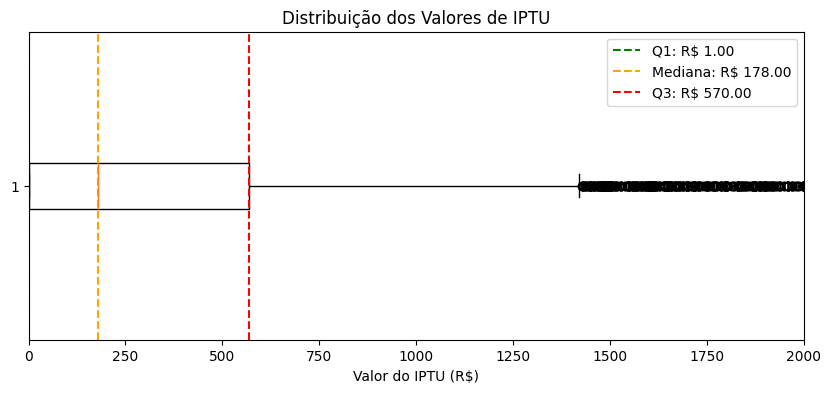

In [ ]:
# Remover valores ausentes apenas para a visualização
iptu = df['IPTU'].dropna()

# Cálculo dos quartis
q1 = iptu.quantile(0.25)
mediana = iptu.quantile(0.50)
q3 = iptu.quantile(0.75)

# Boxplot com destaque para os quartis
plt.figure(figsize=(10, 4))

plt.boxplot(iptu, vert=False)

plt.xlim(0, 2000)

plt.axvline(q1, color='green', linestyle='--', label=f'Q1: R$ {q1:,.2f}')
plt.axvline(mediana, color='orange', linestyle='--', label=f'Mediana: R$ {mediana:,.2f}')
plt.axvline(q3, color='red', linestyle='--', label=f'Q3: R$ {q3:,.2f}')

plt.title('Distribuição dos Valores de IPTU')
plt.xlabel('Valor do IPTU (R$)')
plt.legend()

plt.show()

####5.8.3. Conclusões sobre a variável IPTU
A variável IPTU apresenta forte assimetria e diversos valores extremos. Os quartis indicam que 25% dos registros possuem valores de até  1,00, sugerindo possíveis valores simbólicos ou inconsistências de preenchimento. A mediana é de  178,00, enquanto 75% dos registros apresentam valores de até  570,00. Também foi identificado um valor máximo de  9.751.020,00, considerado inconsistente após a análise do respectivo imóvel. Portanto, essa variável exigirá investigação e tratamento antes de sua possível utilização no modelo de predição.

###5.9. Análise da variável ***data***

####5.9.1. Identificação da variável data

In [ ]:
df['date'].value_counts().head(10)

,count
date,
24/04/2024,10134
25/04/2024,6360
22/04/2024,2382
23/04/2024,2105
20/04/2024,1299
21/04/2024,584
19/04/2024,552
14/04/2024,7
15/04/2024,3


In [ ]:
df['date'].dtype

dtype('O')

A variável:

possui datas preenchidas;
está armazenada como texto (object);
apresenta datas no padrão brasileiro DD/MM/AAAA;


####5.9.2. Análise Gráfica da variável date

In [ ]:
# Converter a coluna para formato de data
df['date'] = pd.to_datetime(df['date'], dayfirst=True)

# Contagem de anúncios por data
contagem_datas = (
    df['date']
    .value_counts()
    .sort_index()
)


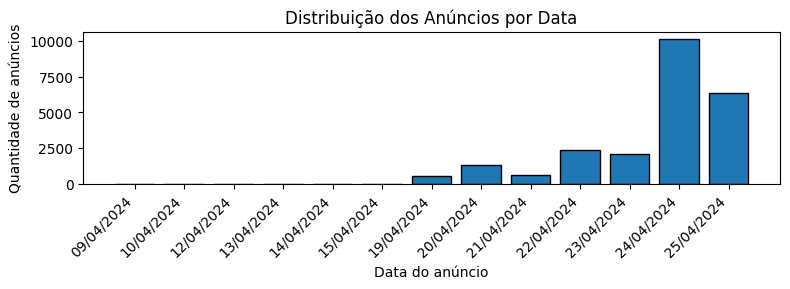

In [ ]:
# Formatação das datas exibidas no eixo X
rotulos_datas = [data.strftime('%d/%m/%Y') for data in contagem_datas.index]

plt.figure(figsize=(8, 3))

plt.bar(
    rotulos_datas,
    contagem_datas.values,
    edgecolor='black'
)

plt.title('Distribuição dos Anúncios por Data')
plt.xlabel('Data do anúncio')
plt.ylabel('Quantidade de anúncios')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

####5.9.3. Conclusões sobre a variável date
A variável date apresenta datas válidas, armazenadas originalmente como texto no padrão brasileiro. Os registros estão concentrados principalmente nos dias 24 e 25 de abril de 2024, indicando a coleta desses dados em um período curto. Essa limitação impede análises sobre variações de preço ao longo do tempo. Para o futuro sistema de predição, a variável possui pouca relevância e poderá ser descartada na etapa de tratamento dos dados.

###5.10. Análises da variável ***location***

####5.10.1. Identificação da variável ***location***

In [ ]:
df['location'].value_counts().head(15)

,count
location,
"São Paulo, Bela Vista",965
"São Paulo, Santa Cecília",907
"São Paulo, Perdizes",813
"São Paulo, Pinheiros",788
"São Paulo, Aclimação",695
"São Paulo, Consolação",610
"São Paulo, Santana",569
"São Paulo, Barra Funda",408
"São Paulo, Cambuci",396


Variável ***location*** está consistente, não demonstra nenhum erro ou problema detectado.

In [ ]:
# Quantidade de localizações distintas
quantidade_localizacoes = df['location'].nunique()

print(f'Quantidade de localizações diferentes: {quantidade_localizacoes}')

Quantidade de localizações diferentes: 941


####5.10.2 Comparação com a variável bairro

In [ ]:
# Extrair de location o texto após a vírgula
bairro_extraido = (
    df['location']
    .str.split(',', n=1)
    .str[-1]
    .str.strip()
)

# Comparar com a coluna bairro
comparacao = bairro_extraido == df['bairro'].str.strip()

print(f'Registros com informações iguais: {comparacao.sum()}')
print(f'Registros com informações diferentes: {(~comparacao).sum()}')
print(f'Percentual de correspondência: {comparacao.mean() * 100:.2f}%')


Registros com informações iguais: 22628
Registros com informações diferentes: 805
Percentual de correspondência: 96.56%


####5.10.3. Análise gráfica

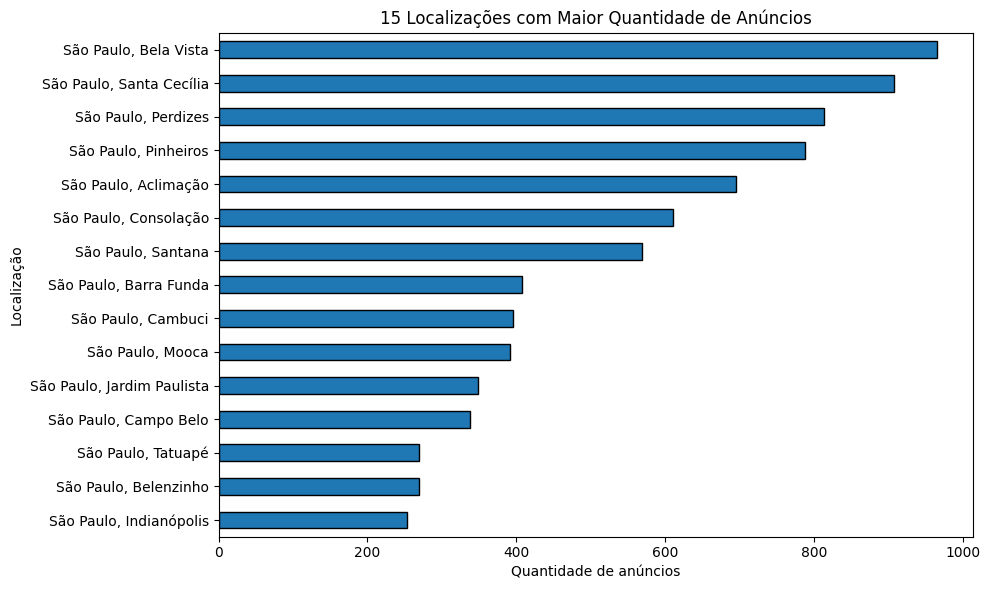

In [ ]:
# Selecionar as 15 localizações mais frequentes
principais_localizacoes = df['location'].value_counts().head(15)

# Gráfico de barras horizontais
plt.figure(figsize=(10, 6))

principais_localizacoes.sort_values().plot(
    kind='barh',
    edgecolor='black'
)

plt.title('15 Localizações com Maior Quantidade de Anúncios')
plt.xlabel('Quantidade de anúncios')
plt.ylabel('Localização')

plt.tight_layout()
plt.show()

####5.10.3 Conclusões sobre a variável location
A variável location apresenta boa diversidade geográfica, com 941 localizações distintas entre os 23.433 registros. A comparação com a variável bairro revelou correspondência em 96,56% dos registros, indicando forte redundância entre as duas colunas. Entretanto, 805 registros apresentaram informações diferentes, que deverão ser investigadas na etapa de tratamento antes da decisão sobre qual variável será mantida no modelo. A localização possui grande relevância para a predição dos preços, mas sua elevada quantidade de categorias também exigirá atenção durante a preparação dos dados.

###5.11. Análise variável ***categoria***

####5.11.1. Identificação da variável categoria

In [ ]:
df['Categoria'].value_counts()

,count
Categoria,
Apartamentos,18073
Casas,5360


A variável apresenta apenas as categorias Apartamentos e Casas. Entretanto, a análise do conteúdo dos anúncios indica que essas classificações nem sempre representam corretamente a finalidade do imóvel.

####5.11.2. Análise gráfica da variável categoria

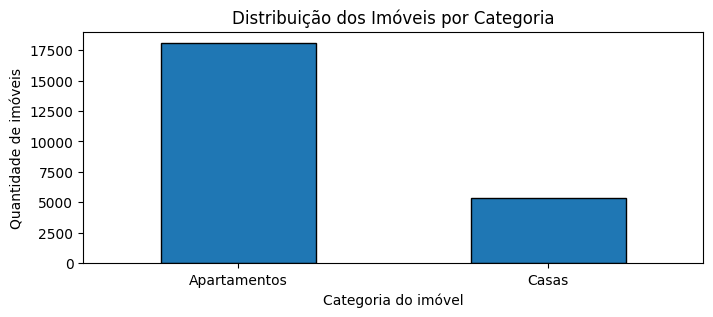

In [ ]:
# Contagem dos imóveis por categoria
contagem_categorias = df['Categoria'].value_counts()

# Gráfico de barras
plt.figure(figsize=(8, 3))

contagem_categorias.plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Distribuição dos Imóveis por Categoria')
plt.xlabel('Categoria do imóvel')
plt.ylabel('Quantidade de imóveis')
plt.xticks(rotation=0)

plt.show()

####5.11.3. Conclusões sobre a variável Categoria
A variável Categoria apresenta apenas as classificações Apartamentos e Casas, com predominância de apartamentos. Embora essas categorias indiquem uma base formada principalmente por imóveis residenciais, análises anteriores identificaram a presença de anúncios comerciais classificados dentro dessas categorias. Portanto, a variável apresenta uma classificação limitada, que nem sempre representa corretamente a finalidade do imóvel anunciado e deverá ser considerada com atenção nas próximas etapas do projeto, muito provavelmente apenas considerando imóveis isolados (casas) e imóveis em edifícios verticais(apartamentos)


###5.12. Análises da variável ***tipo***

####5.12.1. Identificação da variável tipo

In [ ]:
df['Tipo'].value_counts()

,count
Tipo,
Padrão,21694
Cobertura,632
Casa de condomínio,529
Loft,372
Kitnet,109
Casa de vila,76
Duplex ou triplex,18
Venda - casa em rua pública,2
Venda - casa em vila,1


Variável tipo, se apresenta bem consistente, levando a um único ponto de atenção pela existência de apenas 2 casas em rua pública, e apenas 1 casa em vila. Não trata-se de um outlier, mas de um tipo de imóvel pouco frequente.

####5.12.2. Análise gráfica da variável tipo

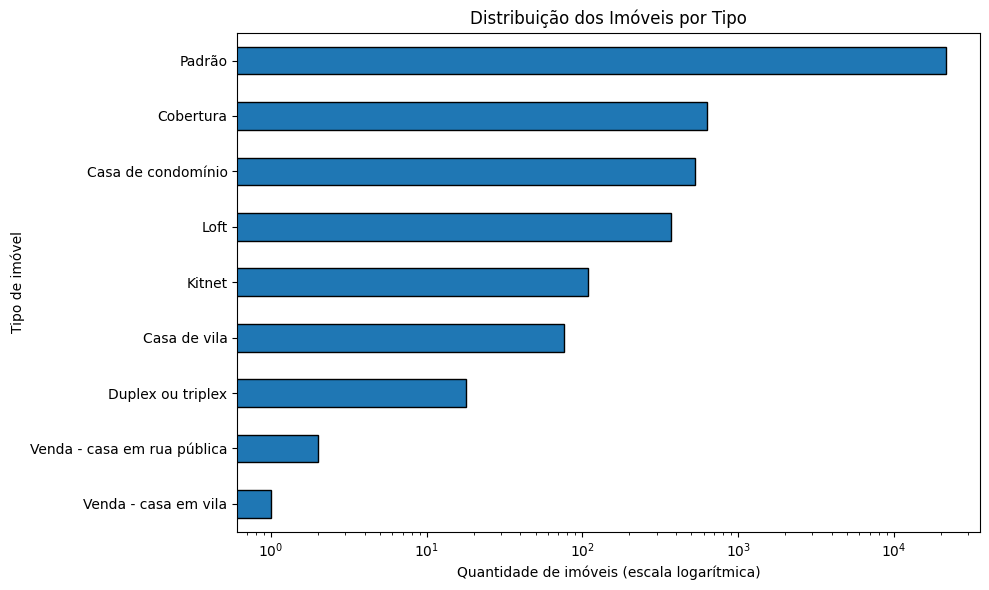

In [ ]:
# Contagem dos imóveis por tipo
contagem_tipos = df['Tipo'].value_counts().sort_values()

# Gráfico com escala logarítmica
plt.figure(figsize=(10, 6))

contagem_tipos.plot(
    kind='barh',
    edgecolor='black'
)

plt.xscale('log')

plt.title('Distribuição dos Imóveis por Tipo')
plt.xlabel('Quantidade de imóveis (escala logarítmica)')
plt.ylabel('Tipo de imóvel')

plt.tight_layout()
plt.show()

####5.12.3. Conclusões sobre a variável tipo
A variável Tipo apresenta forte concentração na categoria Padrão, enquanto os demais tipos de imóveis possuem frequências significativamente menores. Categorias como Cobertura, Casa de condomínio e Loft apresentam maior representatividade entre os tipos alternativos, enquanto outras possuem poucos registros. Esse desequilíbrio deverá ser considerado na etapa de tratamento, pois categorias com baixa frequência podem ter pouca influência no aprendizado do modelo ou exigir agrupamento. Apesar disso, a variável pode ser relevante para a predição dos preços, já que diferentes tipos de imóveis possuem características e padrões de valorização distintos.

###5.13. Análise da variável ***zona***

####5.13.1. Identificação da variável zona

In [ ]:
df['ZONA'].value_counts()

,count
ZONA,
CENTRO,4854
NORTE,4787
OESTE,4765
LESTE,4594
SUL,4433


Variável está consistente, não há valores faltantes, e mostra boa distribuição dos dados nas categorias exibidas.

####5.13.2. Análise Gráfica da variável zona

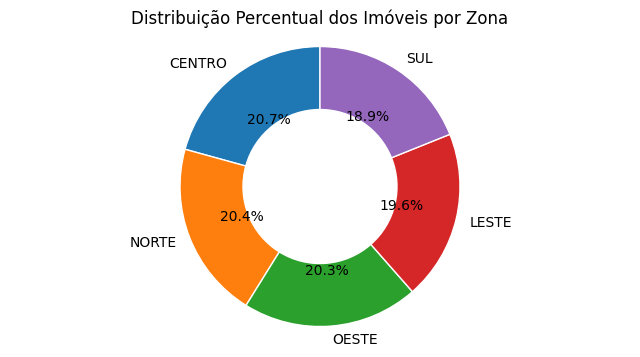

In [ ]:
# Contagem dos imóveis por zona
contagem_zonas = df['ZONA'].value_counts()

# Gráfico de rosca
plt.figure(figsize=(8, 4))

plt.pie(
    contagem_zonas,
    labels=contagem_zonas.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'width': 0.45, 'edgecolor': 'white'}
)

plt.title('Distribuição Percentual dos Imóveis por Zona')
plt.axis('equal')

plt.show()

####5.13.3 Conclusões sobre a variável Zona
A variável ZONA apresenta uma distribuição equilibrada entre as cinco regiões da cidade de São Paulo. A região central concentra 20,7% dos registros, seguida pelas zonas Norte, Oeste, Leste e Sul, todas com participações próximas de 20%. Essa distribuição favorece a representatividade geográfica da base e reduz o risco de o futuro modelo ser influenciado excessivamente por uma única região. Como a localização pode impactar diretamente o valor dos imóveis, essa variável possui grande relevância para o modelo

###5.14. Análises das variáveis binárias

####5.14.1. Distribuição das variáveis binárias (sim ou não)

In [ ]:
variaveis_binarias = [
    'Academia',
    'Elevador',
    'Permitido animais',
    'Piscina',
    'Portaria',
    'Salão de festas',
    'Condomínio fechado',
    'Segurança 24h',
    'Portão eletrônico',
    'Área murada',
    'Área de serviço',
    'Armários na cozinha',
    'Armários no quarto',
    'Churrasqueira',
    'Mobiliado',
    'Quarto de serviço',
    'Ar condicionado',
    'Porteiro 24h',
    'Varanda'
]

df[variaveis_binarias].apply(pd.Series.value_counts).T

,0,1
Academia,18489,4944
Elevador,18409,5024
Permitido animais,14861,8572
Piscina,15282,8151
Portaria,22075,1358
Salão de festas,13956,9477
Condomínio fechado,21059,2374
Segurança 24h,21851,1582
Portão eletrônico,23156,277
Área murada,23389,44


####5.14.2. Análise gráfica conjunta das variáveis binárias

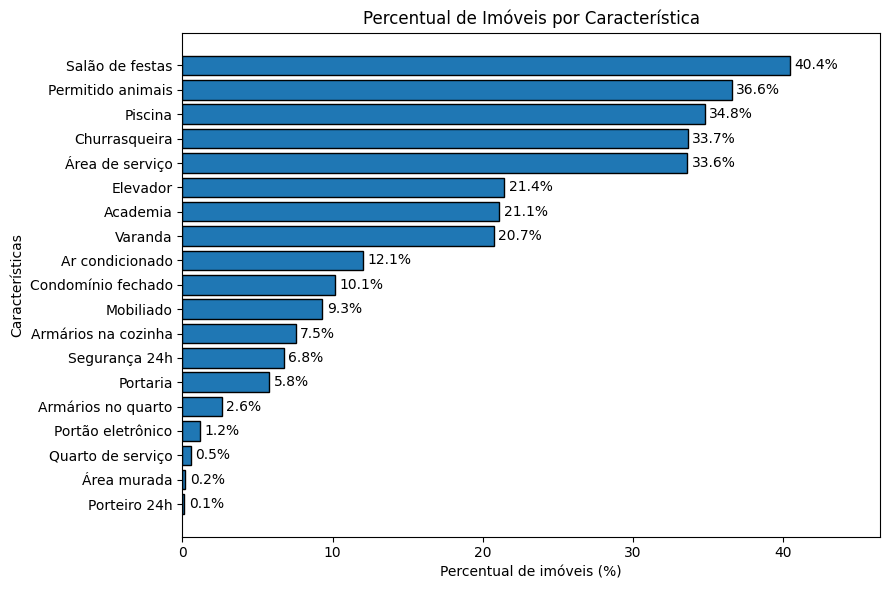

In [ ]:
# Calcular o percentual de presença de cada recurso
percentual_binarias = (
    df[variaveis_binarias].mean() * 100
).sort_values()

# Criar o gráfico
plt.figure(figsize=(9, 6))

barras = plt.barh(
    percentual_binarias.index,
    percentual_binarias.values,
    edgecolor='black'
)

# Adicionar os percentuais ao final das barras
for barra in barras:
    valor = barra.get_width()

    plt.text(
        valor + 0.3,
        barra.get_y() + barra.get_height() / 2,
        f'{valor:.1f}%',
        va='center'
    )

plt.title('Percentual de Imóveis por Característica')
plt.xlabel('Percentual de imóveis (%)')
plt.ylabel('Características')
plt.xlim(0, percentual_binarias.max() + 6)

plt.tight_layout()
plt.show()

####5.14.3 Conclusões sobre as variáveis binárias
As variáveis binárias apresentam frequências bastante distintas. Salão de festas, permitido animais, piscina, churrasqueira e área de serviço são as características mais frequentes. Por outro lado, porteiro 24h, área murada, quarto de serviço e portão eletrônico aparecem em uma parcela reduzida dos anúncios. Essa baixa frequência pode representar características realmente pouco comuns ou limitações no preenchimento dos anúncios. A influência dessas variáveis sobre o preço será avaliada posteriormente por meio de análises relacionais.

###5.15. Análise da variável ***Área útil***

####5.15.1. Análise estatística da variável Área útil

In [ ]:
# Análise estatística da variável Área útil
df['Área útil'].describe()

,Área útil
count,"23.433,00"
mean,"240,42"
std,"7.208,17"
min,"0,00"
25%,"65,00"
50%,"107,00"
75%,"170,00"
max,"608.608,00"


####5.15.2. Identificação de valores extremos

In [ ]:
# Quantidade de registros com área útil igual a zero
quantidade_area_zero = (df['Área útil'] == 0).sum()

print(f'Registros com área útil igual a zero: {quantidade_area_zero}')

# Exibir o registro com a maior área útil
df[df['Área útil'] == df['Área útil'].max()]

Registros com área útil igual a zero: 3


,index,title,price,oldPrice,location,date,destaque,Categoria,Tipo,Condomínio,...,Área de serviço,Armários na cozinha,Armários no quarto,Churrasqueira,Mobiliado,Quarto de serviço,Ar condicionado,Porteiro 24h,Varanda,bairro
9088,9088,Casa à venda no bairro Jardim Petrópolis - São...,7000000,NaN,"São Paulo, Jardim Petrópolis",2024-04-25,False,Casas,Padrão,"5.285,00",...,1,0,0,1,0,0,0,0,0,Jardim Petrópolis
10481,10481,Casa à venda no bairro Jardim Petrópolis - São...,6500000,NaN,"São Paulo, Jardim Petrópolis",2024-04-25,False,Casas,Padrão,"5.285,00",...,1,0,0,0,0,0,0,0,0,Jardim Petrópolis
10487,10487,Casa à venda no bairro Jardim Petrópolis - São...,6000000,NaN,"São Paulo, Jardim Petrópolis",2024-04-25,False,Casas,Padrão,"5.285,00",...,1,0,0,1,0,0,0,0,0,Jardim Petrópolis


In [ ]:
# Visualizar informações principais dos registros com área máxima
df[df['Área útil'] == df['Área útil'].max()][
    ['index', 'title', 'price', 'Área útil', 'location', 'Quartos', 'Banheiros']
]

,index,title,price,Área útil,location,Quartos,Banheiros
9088,9088,Casa à venda no bairro Jardim Petrópolis - São...,7000000,608608,"São Paulo, Jardim Petrópolis",4,5 ou mais
10481,10481,Casa à venda no bairro Jardim Petrópolis - São...,6500000,608608,"São Paulo, Jardim Petrópolis",4,5 ou mais
10487,10487,Casa à venda no bairro Jardim Petrópolis - São...,6000000,608608,"São Paulo, Jardim Petrópolis",4,5 ou mais


Foram identificados três registros com área útil igual a zero e três anúncios com área máxima de 608.608 m². Os anúncios com área máxima apresentam características semelhantes e valores distintos de venda, indicando possível repetição do mesmo imóvel ou erro de preenchimento da área. Como o valor informado é incompatível com as características observadas, esses registros deverão ser investigados e tratados posteriormente, sem realizar alterações nesta etapa de análise.

####5.15.3. Análise gráfica da variável Área útil

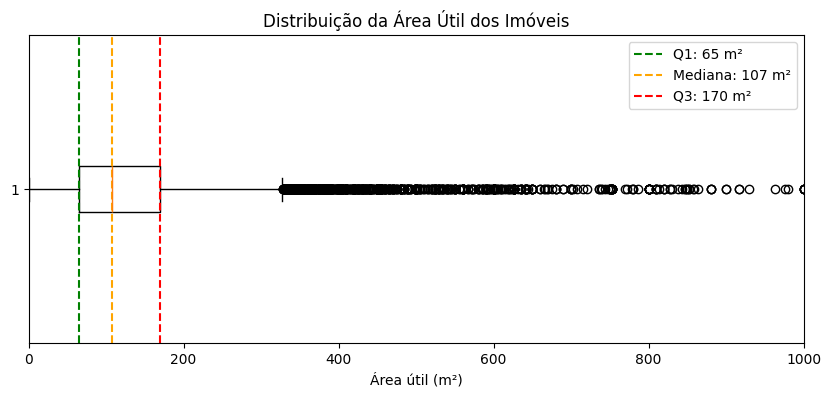

In [ ]:
# Dados da variável Área útil
area_util = df['Área útil'].dropna()

# Cálculo dos quartis
q1 = area_util.quantile(0.25)
mediana = area_util.quantile(0.50)
q3 = area_util.quantile(0.75)

# Boxplot com destaque para os quartis
plt.figure(figsize=(10, 4))

plt.boxplot(area_util, vert=False)

plt.xlim(0, 1000)

plt.axvline(q1, color='green', linestyle='--', label=f'Q1: {q1:,.0f} m²')
plt.axvline(mediana, color='orange', linestyle='--', label=f'Mediana: {mediana:,.0f} m²')
plt.axvline(q3, color='red', linestyle='--', label=f'Q3: {q3:,.0f} m²')

plt.title('Distribuição da Área Útil dos Imóveis')
plt.xlabel('Área útil (m²)')
plt.legend()

plt.show()

####5.15.4. Conclusões sobre a variável Área útil
A variável Área útil apresenta forte assimetria, com 50% dos imóveis concentrados entre 65 m² e 170 m² e mediana de 107 m². Foram identificados três registros com área igual a zero e três anúncios com área de 608.608 m², valor considerado potencialmente inconsistente. Embora áreas elevadas possam representar imóveis de grande porte, os valores extremos deverão ser investigados na etapa de tratamento. De modo geral, a área útil possui grande relevância para o futuro modelo de predição, pois tende a exercer influência direta sobre o preço dos imóveis.

###5.16. Variáveis não selecionadas para o projeto
Algumas variáveis disponíveis na base de dados não foram analisadas individualmente por não apresentarem relação direta com o objetivo do projeto ou por não estarem previstas como informações de entrada no futuro sistema de predição. Essa seleção preliminar busca concentrar as análises nas características que poderão contribuir efetivamente para estimar o preço dos imóveis. A exclusão definitiva dessas variáveis será realizada posteriormente, no notebook destinado ao tratamento e à preparação dos dados.

#### 5.16.1. Identificação e justificativa das variáveis

- **index:** representa apenas a identificação numérica dos registros e não descreve nenhuma característica do imóvel.

- **title:** contém o título textual dos anúncios. Sua utilização exigiria técnicas de Processamento de Linguagem Natural, que não fazem parte do escopo atual do projeto.

- **destaque:** indica se o anúncio recebeu destaque na plataforma, representando uma característica comercial da publicação e não uma característica física ou geográfica do imóvel.

- **Detalhes do imóvel:** contém informações textuais não estruturadas, sendo que parte dessas características já está representada pelas variáveis binárias disponíveis na base.

- **Detalhes do condomínio:** também possui conteúdo textual não estruturado e informações parcialmente representadas pelas variáveis binárias relacionadas à infraestrutura do condomínio.

#### 5.16.2. Conclusões sobre as variáveis não selecionadas

As variáveis identificadas nesta seção não serão consideradas inicialmente no desenvolvimento do modelo de Machine Learning. Essa decisão está relacionada à ausência de contribuição direta para o objetivo do projeto, à presença de textos não estruturados ou à redundância com outras informações disponíveis.

As variáveis permanecerão na base durante este notebook de análise, sendo removidas somente no notebook destinado ao tratamento e à preparação dos dados.




##***6.Valores Ausentes***
Nesta etapa, será analisada a presença de valores ausentes na base de dados, identificando a quantidade e o percentual de dados faltantes em cada variável. Essa análise permitirá avaliar o impacto dessas ausências e auxiliar, posteriormente, na definição das estratégias de tratamento, como exclusão, preenchimento ou manutenção dos valores ausentes.

In [ ]:
# Tabela com quantidade e percentual de valores ausentes
analise_ausentes = pd.DataFrame({
    'Quantidade Ausente': df.isnull().sum(),
    'Percentual Ausente (%)': (df.isnull().sum() / len(df)) * 100
})

# Exibir somente colunas que possuem valores ausentes
analise_ausentes = analise_ausentes[
    analise_ausentes['Quantidade Ausente'] > 0
].sort_values(by='Percentual Ausente (%)', ascending=False)

analise_ausentes

,Quantidade Ausente,Percentual Ausente (%)
oldPrice,22543,"96,20"
Detalhes do imóvel,7135,"30,45"
Detalhes do condomínio,7108,"30,33"
IPTU,201,"0,86"
Condomínio,167,"0,71"
Banheiros,6,"0,03"


A análise acima, identificou valores ausentes em seis variáveis. A coluna ***oldPrice*** possui 96,20% de dados faltantes, indicando pouca utilidade para o modelo e possível exclusão futura. As colunas ***Detalhes do imóvel e Detalhes do condomínio*** apresentam aproximadamente 30% de ausência e precisarão ser avaliadas conforme sua relevância. Já IPTU, Condomínio e Banheiros possuem poucos valores ausentes. Essas informações orientarão as decisões de exclusão, preenchimento ou manutenção das variáveis na etapa de tratamento dos dados.

##***7. Registros Duplicados***
Nesta etapa, será verificada a existência de registros duplicados na base de dados. Essa análise permitirá identificar possíveis anúncios repetidos, que podem distorcer os resultados estatísticos e influenciar o treinamento do modelo de Machine Learning. A decisão sobre a exclusão desses registros será realizada posteriormente, na etapa de tratamento dos dados.

In [ ]:
# Verificar registros duplicados desconsiderando a coluna index
duplicados_sem_index = df.drop(columns=['index']).duplicated().sum()

print(f'Registros duplicados desconsiderando o index: {duplicados_sem_index}')


Registros duplicados desconsiderando o index: 1784


In [ ]:
# Identificar e exibir alguns registros duplicados
colunas_analise = df.columns.drop('index')

registros_duplicados = df[
    df.duplicated(subset=colunas_analise, keep=False)
].sort_values(by='title')

registros_duplicados.head(10)

,index,title,price,oldPrice,location,date,destaque,Categoria,Tipo,Condomínio,...,Área de serviço,Armários na cozinha,Armários no quarto,Churrasqueira,Mobiliado,Quarto de serviço,Ar condicionado,Porteiro 24h,Varanda,bairro
5070,5070,"""Casa dos Sonhos: Charmosa Residência com Jard...",1250000,NaN,"São Paulo, Parque dos Príncipes",2024-04-25,False,Casas,Padrão,"640,00",...,0,0,0,0,0,0,0,0,0,Parque dos Príncipes
5095,5095,"""Casa dos Sonhos: Charmosa Residência com Jard...",1250000,NaN,"São Paulo, Parque dos Príncipes",2024-04-25,False,Casas,Padrão,"640,00",...,0,0,0,0,0,0,0,0,0,Parque dos Príncipes
20286,20286,"""Residencial Parada Inglesa: O Refúgio do Conf...",235000,NaN,"São Paulo, Parada Inglesa",2024-04-21,False,Apartamentos,Padrão,"0,00",...,0,0,0,0,0,0,0,0,0,Parada Inglesa
20285,20285,"""Residencial Parada Inglesa: O Refúgio do Conf...",235000,NaN,"São Paulo, Parada Inglesa",2024-04-21,False,Apartamentos,Padrão,"0,00",...,0,0,0,0,0,0,0,0,0,Parada Inglesa
20267,20267,"""Residencial Parada Inglesa: O Refúgio do Conf...",235000,NaN,"São Paulo, Parada Inglesa",2024-04-21,False,Apartamentos,Padrão,"0,00",...,0,0,0,0,0,0,0,0,0,Parada Inglesa
20270,20270,"""Residencial Parada Inglesa: O Refúgio do Conf...",235000,NaN,"São Paulo, Parada Inglesa",2024-04-21,False,Apartamentos,Padrão,"0,00",...,0,0,0,0,0,0,0,0,0,Parada Inglesa
20272,20272,"""Residencial Parada Inglesa: O Refúgio do Conf...",235000,NaN,"São Paulo, Parada Inglesa",2024-04-21,False,Apartamentos,Padrão,"0,00",...,0,0,0,0,0,0,0,0,0,Parada Inglesa
20273,20273,"""Residencial Parada Inglesa: O Refúgio do Conf...",235000,NaN,"São Paulo, Parada Inglesa",2024-04-21,False,Apartamentos,Padrão,"0,00",...,0,0,0,0,0,0,0,0,0,Parada Inglesa
20274,20274,"""Residencial Parada Inglesa: O Refúgio do Conf...",235000,NaN,"São Paulo, Parada Inglesa",2024-04-21,False,Apartamentos,Padrão,"0,00",...,0,0,0,0,0,0,0,0,0,Parada Inglesa
20275,20275,"""Residencial Parada Inglesa: O Refúgio do Conf...",235000,NaN,"São Paulo, Parada Inglesa",2024-04-21,False,Apartamentos,Padrão,"0,00",...,0,0,0,0,0,0,0,0,0,Parada Inglesa


In [ ]:
# Total de registros envolvidos em duplicidades
total_envolvidos = registros_duplicados.shape[0]

# Total de registros após remover as repetições
total_sem_duplicados = df.drop_duplicates(
    subset=colunas_analise
).shape[0]

print(f'Registros envolvidos em duplicidades: {total_envolvidos}')
print(f'Registros restantes após remover duplicados: {total_sem_duplicados}')

Registros envolvidos em duplicidades: 3139
Registros restantes após remover duplicados: 21649


###7.1 Conclusões sobre os registros duplicados
A análise identificou ***1.784 registros duplicado***, desconsiderando a coluna de índice. Ao considerar também as primeiras ocorrências, ***3.139 registros*** estão envolvidos em grupos de duplicidade. A permanência dessas repetições pode distorcer as análises e influenciar o treinamento do modelo, aumentando artificialmente a importância de determinados imóveis. Portanto, recomenda-se remover apenas as ocorrências excedentes na etapa de tratamento, preservando uma ocorrência de cada anúncio.

In [ ]:
# Extrair de location o texto após a vírgula
bairro_extraido = (
    df['location']
    .str.split(',', n=1)
    .str[-1]
    .str.strip()
)

# Comparar com a coluna bairro
comparacao = bairro_extraido == df['bairro'].str.strip()

print(f'Registros com informações iguais: {comparacao.sum()}')
print(f'Registros com informações diferentes: {(~comparacao).sum()}')
print(f'Percentual de correspondência: {comparacao.mean() * 100:.2f}%')

Registros com informações iguais: 22628
Registros com informações diferentes: 805
Percentual de correspondência: 96.56%


## ***8. Análises relacionais entre as variáveis***

Nesta etapa, serão realizadas análises relacionando a variável-alvo **price** com as principais características dos imóveis. O objetivo é identificar padrões, associações e possíveis influências sobre os preços, contribuindo para a seleção das variáveis que serão utilizadas futuramente no modelo de Machine Learning.

### 8.1. Relação entre preço e área útil

Inicialmente, será analisada a relação entre o **preço do imóvel** e sua **área útil**. Essa comparação permitirá verificar se imóveis com áreas maiores tendem a apresentar preços mais elevados, além de possibilitar a identificação de padrões, dispersões e valores extremos entre as duas variáveis.

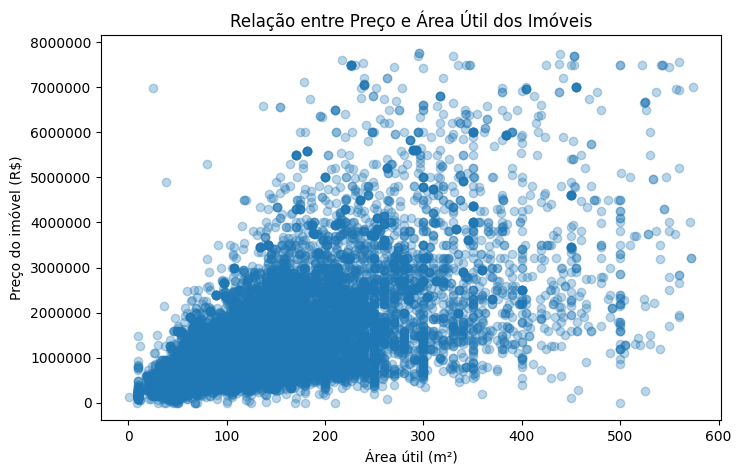

In [ ]:
# Definir limites visuais pelo percentil 99
limite_area = df['Área útil'].quantile(0.99)
limite_preco = df['price'].quantile(0.99)

# Selecionar dados apenas para visualização
dados_visualizacao = df[
    (df['Área útil'] > 0) &
    (df['Área útil'] <= limite_area) &
    (df['price'] > 0) &
    (df['price'] <= limite_preco)
]

# Gráfico de dispersão
plt.figure(figsize=(8, 5))

plt.scatter(
    dados_visualizacao['Área útil'],
    dados_visualizacao['price'],
    alpha=0.3
)

plt.title('Relação entre Preço e Área Útil dos Imóveis')
plt.xlabel('Área útil (m²)')
plt.ylabel('Preço do imóvel (R$)')

plt.ticklabel_format(style='plain', axis='y')

plt.show()

In [ ]:
# Correlação entre preço e área útil
correlacao_preco_area = df['price'].corr(df['Área útil'])

print(f'Correlação entre preço e área útil: {correlacao_preco_area:.4f}')

Correlação entre preço e área útil: 0.0400


In [ ]:
# Correlação considerando os mesmos limites utilizados no gráfico
correlacao_filtrada = dados_visualizacao['price'].corr(
    dados_visualizacao['Área útil']
)

print(
    f'Correlação entre preço e área útil nos dados visualizados: '
    f'{correlacao_filtrada:.4f}'
)

Correlação entre preço e área útil nos dados visualizados: 0.6830


#### 8.1.1. Conclusões sobre a relação entre preço e área útil

O gráfico de dispersão indica que imóveis com maior **área útil** tendem a apresentar preços mais elevados. Entretanto, a dispersão observada demonstra que a área não explica o preço isoladamente, pois outras características também influenciam o valor dos imóveis.

A correlação calculada com todos os registros foi de apenas **0,0400**, resultado fortemente afetado pelos valores extremos existentes na base. Ao considerar os mesmos limites utilizados no gráfico, correspondentes ao percentil 99, a correlação passou para **0,6830**, indicando uma relação positiva de intensidade moderada a forte entre as variáveis.

Esses resultados demonstram que a **Área útil** possui grande relevância para o futuro modelo de predição. Também reforçam a necessidade de investigar e tratar adequadamente os valores extremos antes da etapa de modelagem.

### 8.2. Relação entre preço e quantidade de quartos

Nesta etapa, será analisada a relação entre o **preço dos imóveis** e a **quantidade de quartos**. A comparação permitirá verificar como os preços se distribuem entre as diferentes categorias, identificando possíveis diferenças na mediana, na dispersão e na ocorrência de valores extremos.

Essa análise contribuirá para avaliar a relevância da variável **Quartos** no futuro modelo de predição de preços.

/tmp/ipykernel_3070/3849144610.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


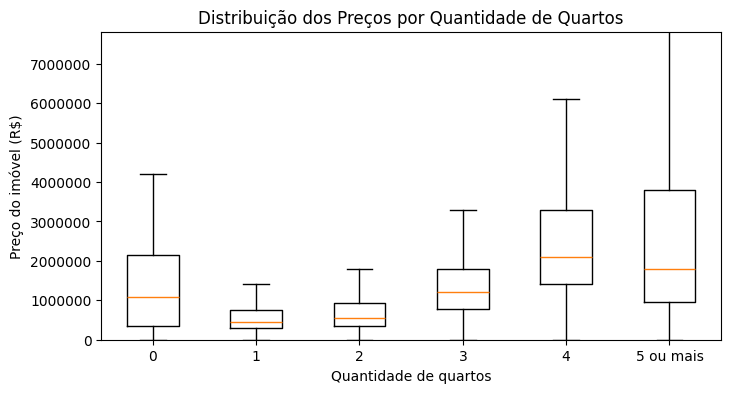

In [ ]:
# Ordem das categorias de quartos
ordem_quartos = ['0', '1', '2', '3', '4', '5 ou mais']

# Organizar os preços por quantidade de quartos
dados_quartos = [
    df.loc[df['Quartos'].astype(str) == categoria, 'price']
    for categoria in ordem_quartos
]

# Limite visual pelo percentil 99 do preço
limite_preco = df['price'].quantile(0.99)

# Criar o boxplot
plt.figure(figsize=(8, 4))

plt.boxplot(
    dados_quartos,
    labels=ordem_quartos,
    showfliers=False
)

plt.ylim(0, limite_preco)

plt.title('Distribuição dos Preços por Quantidade de Quartos')
plt.xlabel('Quantidade de quartos')
plt.ylabel('Preço do imóvel (R$)')

plt.ticklabel_format(style='plain', axis='y')

plt.show()

#### 8.2.1. Conclusões sobre a relação entre preço e quantidade de quartos

A análise demonstra que a quantidade de quartos possui relação com o preço dos imóveis. As categorias de **um e dois quartos** apresentam menores preços medianos, enquanto os imóveis com **três e quatro quartos** possuem valores tipicamente mais elevados.

Os imóveis com **cinco ou mais quartos** apresentam ampla variação de preços, indicando diferenças importantes entre os imóveis pertencentes a essa categoria. Já os registros com **zero quartos** devem ser interpretados com cautela, devido à pequena quantidade de imóveis disponíveis nesse grupo.

Portanto, a variável **Quartos** apresenta relevância para o futuro modelo de predição. Entretanto, a quantidade de quartos não determina o preço isoladamente, sendo necessário considerar sua relação com outras características, como área útil, localização e tipo do imóvel.

### 8.3. Relação entre preço e quantidade de banheiros

Nesta etapa, será analisada a relação entre o **preço dos imóveis** e a **quantidade de banheiros**. A comparação permitirá verificar como os preços se distribuem entre as diferentes categorias, observando diferenças na mediana, na dispersão e na amplitude dos valores.

Essa análise contribuirá para avaliar a relevância da variável **Banheiros** no futuro modelo de predição de preços.

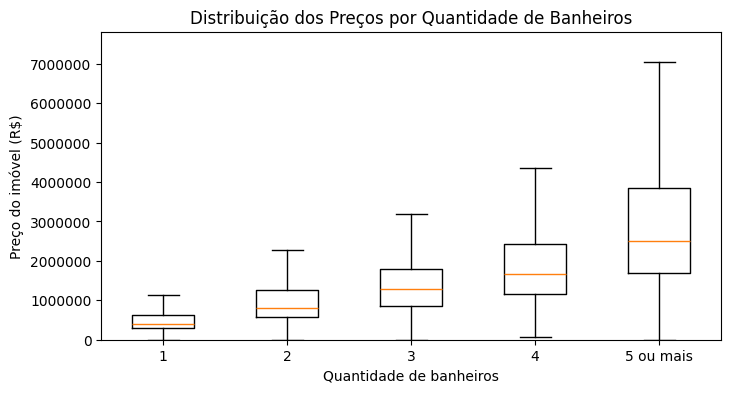

In [ ]:
# Ordem das categorias de banheiros
ordem_banheiros = ['1', '2', '3', '4', '5 ou mais']

# Organizar os preços por quantidade de banheiros
dados_banheiros = [
    df.loc[df['Banheiros'].astype(str) == categoria, 'price']
    for categoria in ordem_banheiros
]

# Limite visual pelo percentil 99 do preço
limite_preco = df['price'].quantile(0.99)

# Criar o boxplot
plt.figure(figsize=(8, 4))

plt.boxplot(
    dados_banheiros,
    tick_labels=ordem_banheiros,
    showfliers=False
)

plt.ylim(0, limite_preco)

plt.title('Distribuição dos Preços por Quantidade de Banheiros')
plt.xlabel('Quantidade de banheiros')
plt.ylabel('Preço do imóvel (R$)')

plt.ticklabel_format(style='plain', axis='y')

plt.show()

#### 8.3.1. Conclusões sobre a relação entre preço e quantidade de banheiros

A análise demonstra uma relação positiva entre a **quantidade de banheiros** e o **preço dos imóveis**. As medianas aumentam progressivamente entre as categorias, indicando que imóveis com maior número de banheiros tendem a apresentar preços mais elevados.

Também é possível observar maior dispersão dos preços nas categorias com quatro e cinco ou mais banheiros. Essa variação indica que imóveis com muitos banheiros podem apresentar características bastante diferentes em relação à área, ao padrão construtivo, ao tipo e à localização.

Portanto, a variável **Banheiros** apresenta potencial relevância para o futuro modelo de predição. Entretanto, sua influência deverá ser analisada em conjunto com outras características do imóvel.

### 8.4. Relação entre preço e quantidade de vagas na garagem

Nesta etapa, será analisada a relação entre o **preço dos imóveis** e a **quantidade de vagas na garagem**. A comparação permitirá observar como a mediana e a dispersão dos preços variam entre as diferentes categorias.

Essa análise contribuirá para verificar se imóveis com maior quantidade de vagas tendem a apresentar preços mais elevados e para avaliar a relevância dessa variável no futuro modelo de predição.

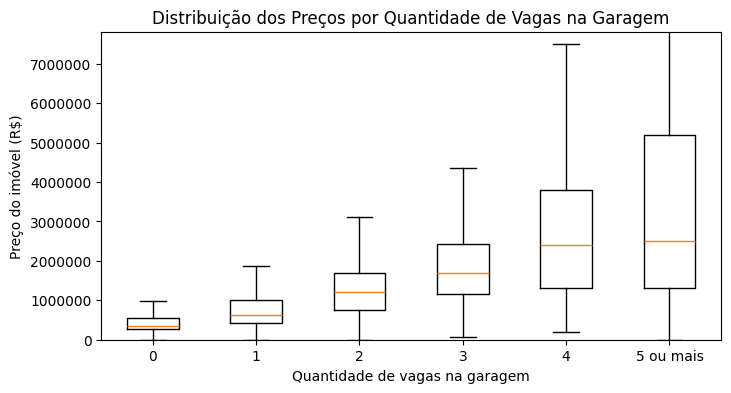

In [ ]:
# Ordem das categorias de vagas na garagem
ordem_vagas = ['0', '1', '2', '3', '4', '5 ou mais']

# Organizar os preços por quantidade de vagas
dados_vagas = [
    df.loc[df['Vagas na garagem'].astype(str) == categoria, 'price']
    for categoria in ordem_vagas
]

# Limite visual pelo percentil 99 do preço
limite_preco = df['price'].quantile(0.99)

# Criar o boxplot
plt.figure(figsize=(8, 4))

plt.boxplot(
    dados_vagas,
    tick_labels=ordem_vagas,
    showfliers=False
)

plt.ylim(0, limite_preco)

plt.title('Distribuição dos Preços por Quantidade de Vagas na Garagem')
plt.xlabel('Quantidade de vagas na garagem')
plt.ylabel('Preço do imóvel (R$)')

plt.ticklabel_format(style='plain', axis='y')

plt.show()

#### 8.4.1. Conclusões sobre a relação entre preço e quantidade de vagas na garagem

A análise demonstra uma relação positiva entre a **quantidade de vagas na garagem** e o **preço dos imóveis**. As medianas aumentam progressivamente entre as categorias, indicando que imóveis com mais vagas tendem a apresentar preços mais elevados.

Também se observa maior dispersão dos preços nas categorias com quatro e cinco ou mais vagas. Isso demonstra que esses grupos reúnem imóveis com diferentes padrões, áreas e localizações.

Portanto, a variável **Vagas na garagem** apresenta relevância para o futuro modelo de predição. Entretanto, sua influência deverá ser analisada em conjunto com outras características dos imóveis.

### 8.5. Relação entre preço e valor do condomínio

Nesta etapa, será analisada a relação entre o **preço dos imóveis** e o **valor do condomínio**. O objetivo é verificar se imóveis com condomínios mais elevados também tendem a apresentar maiores preços de venda.

A análise será realizada por meio de um gráfico de dispersão e do cálculo da correlação entre as variáveis. Devido à presença de valores extremos e possíveis inconsistências na variável **Condomínio**, serão utilizados limites visuais para facilitar a interpretação, sem alterar ou excluir registros da base original.

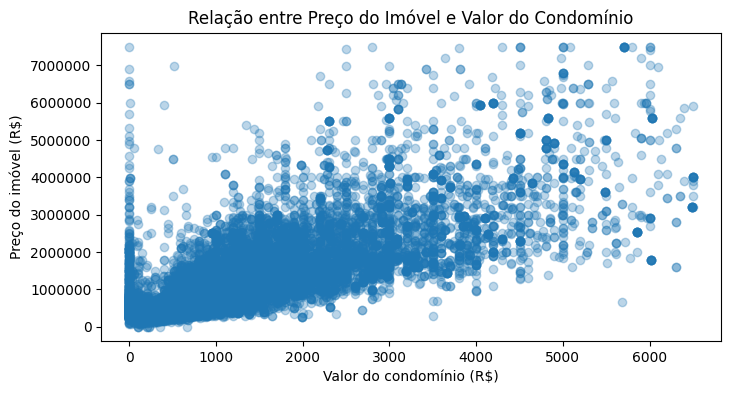

In [ ]:
# Selecionar registros válidos para a análise
dados_condominio = df[
    (df['price'] > 0) &
    (df['Condomínio'].notna()) &
    (df['Condomínio'] > 0)
].copy()

# Definir limites pelo percentil 99
limite_preco = dados_condominio['price'].quantile(0.99)
limite_condominio = dados_condominio['Condomínio'].quantile(0.99)

# Selecionar os dados apenas para visualização
dados_condominio_visualizacao = dados_condominio[
    (dados_condominio['price'] <= limite_preco) &
    (dados_condominio['Condomínio'] <= limite_condominio)
]

# Criar o gráfico de dispersão
plt.figure(figsize=(8, 4))

plt.scatter(
    dados_condominio_visualizacao['Condomínio'],
    dados_condominio_visualizacao['price'],
    alpha=0.3
)

plt.title('Relação entre Preço do Imóvel e Valor do Condomínio')
plt.xlabel('Valor do condomínio (R$)')
plt.ylabel('Preço do imóvel (R$)')

plt.ticklabel_format(style='plain', axis='both')

plt.show()

In [ ]:
# Correlação entre preço e condomínio nos dados visualizados
correlacao_preco_condominio = (
    dados_condominio_visualizacao['price']
    .corr(dados_condominio_visualizacao['Condomínio'])
)

print(
    f'Correlação entre preço e condomínio: '
    f'{correlacao_preco_condominio:.4f}'
)

Correlação entre preço e condomínio: 0.7511


#### 8.5.1. Conclusões sobre a relação entre preço e valor do condomínio

O gráfico de dispersão demonstra uma tendência de crescimento do preço dos imóveis conforme aumenta o valor do condomínio. A correlação calculada foi de **0,7511**, indicando uma relação positiva forte entre as duas variáveis.

Apesar dessa associação, observa-se uma dispersão considerável dos registros, demonstrando que imóveis com valores semelhantes de condomínio podem apresentar preços diferentes. Essa variação pode estar relacionada à área útil, localização, categoria, tipo e demais características dos imóveis.

Portanto, a variável **Condomínio** apresenta potencial relevância para o futuro modelo de predição. Entretanto, os valores extremos, ausentes e potencialmente inconsistentes deverão ser tratados antes da modelagem.

### 8.6. Relação entre preço e zona da cidade

Nesta etapa, será analisada a relação entre o **preço dos imóveis** e a **zona da cidade** em que estão localizados. A comparação permitirá identificar diferenças na mediana e na dispersão dos preços entre as regiões **Centro, Norte, Sul, Leste e Oeste**.

Essa análise contribuirá para avaliar a influência da localização geográfica sobre o preço dos imóveis e a relevância da variável **ZONA** para o futuro modelo de predição.

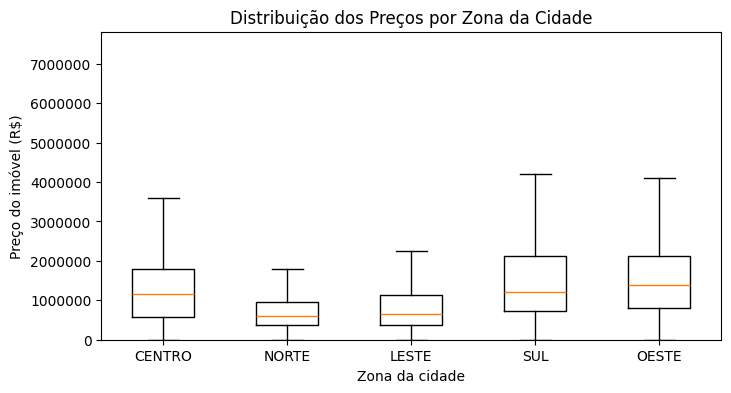

In [ ]:
# Ordem das zonas
ordem_zonas = ['CENTRO', 'NORTE', 'LESTE', 'SUL', 'OESTE']

# Organizar os preços por zona
dados_zonas = [
    df.loc[df['ZONA'] == zona, 'price']
    for zona in ordem_zonas
]

# Limite visual pelo percentil 99 do preço
limite_preco = df['price'].quantile(0.99)

# Criar o boxplot
plt.figure(figsize=(8, 4))

plt.boxplot(
    dados_zonas,
    tick_labels=ordem_zonas,
    showfliers=False
)

plt.ylim(0, limite_preco)

plt.title('Distribuição dos Preços por Zona da Cidade')
plt.xlabel('Zona da cidade')
plt.ylabel('Preço do imóvel (R$)')

plt.ticklabel_format(style='plain', axis='y')

plt.show()

#### 8.6.1. Conclusões sobre a relação entre preço e zona da cidade

A análise demonstra que a **zona da cidade** possui relação relevante com o preço dos imóveis. A **Zona Oeste** apresenta a maior mediana de preços, seguida pelas zonas **Sul** e **Centro**. As zonas **Norte** e **Leste**, por sua vez, apresentam menores preços medianos.

Também foi observada maior dispersão dos preços nas zonas Oeste, Sul e Centro, indicando maior variedade de imóveis e faixas de preço nessas regiões. Essas diferenças demonstram que a localização geográfica influencia o valor dos imóveis.

Portanto, a variável **ZONA** apresenta grande relevância para o futuro modelo de predição, pois permite representar diferenças gerais de valorização entre as regiões da cidade de São Paulo.

### 8.7. Relação entre preço e categoria do imóvel

Nesta etapa, será analisada a relação entre o **preço dos imóveis** e sua **categoria**, comparando os registros classificados como **Casas** e **Apartamentos**.

A análise permitirá identificar diferenças na mediana e na dispersão dos preços entre as duas categorias, contribuindo para avaliar a relevância da variável **Categoria** no futuro modelo de predição.

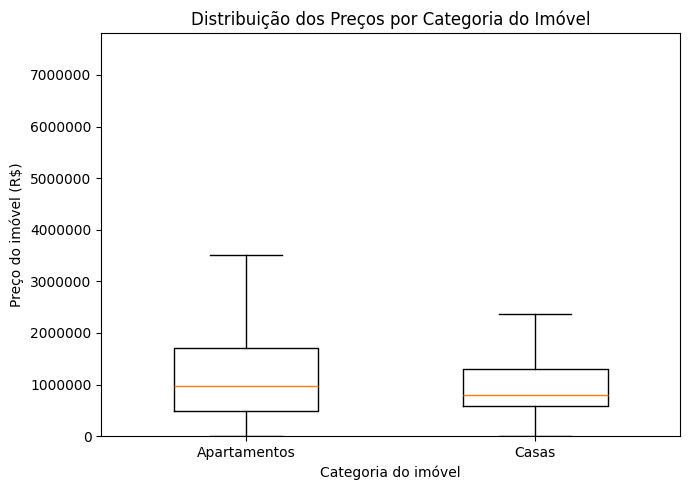

In [ ]:
# Ordem das categorias
ordem_categorias = ['Apartamentos', 'Casas']

# Organizar os preços por categoria
dados_categorias = [
    df.loc[df['Categoria'] == categoria, 'price']
    for categoria in ordem_categorias
]

# Limite visual pelo percentil 99 do preço
limite_preco = df['price'].quantile(0.99)

# Criar o boxplot
plt.figure(figsize=(7, 5))

plt.boxplot(
    dados_categorias,
    tick_labels=ordem_categorias,
    showfliers=False,
    widths=0.5
)

plt.ylim(0, limite_preco)

plt.title('Distribuição dos Preços por Categoria do Imóvel')
plt.xlabel('Categoria do imóvel')
plt.ylabel('Preço do imóvel (R$)')

plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()

#### 8.7.1. Conclusões sobre a relação entre preço e categoria do imóvel

A análise demonstra diferenças entre os preços dos imóveis classificados como **Apartamentos** e **Casas**. Os apartamentos apresentam maior preço mediano e maior dispersão dos valores, enquanto as casas possuem mediana ligeiramente menor e preços mais concentrados.

Esses resultados indicam que a variável **Categoria** pode contribuir para o futuro modelo de predição. Entretanto, a interpretação deve considerar que análises anteriores identificaram limitações nessa classificação, pois alguns anúncios podem não representar corretamente a finalidade ou as características do imóvel.

Portanto, a variável deverá ser utilizada em conjunto com outras informações, como área útil, localização, tipo do imóvel, quantidade de quartos e vagas na garagem.

### 8.8. Relação entre preço e tipo do imóvel

Nesta etapa, será analisada a relação entre o **preço dos imóveis** e a variável **Tipo**. A comparação permitirá observar diferenças na mediana e na dispersão dos preços entre categorias como **Padrão, Cobertura, Casa de condomínio, Loft, Kitnet** e outros tipos disponíveis na base.

Como algumas categorias possuem poucos registros, os resultados deverão ser interpretados com cautela. Essa análise contribuirá para avaliar a relevância da variável **Tipo** no futuro modelo de predição e identificar categorias que poderão exigir agrupamento durante o tratamento dos dados.

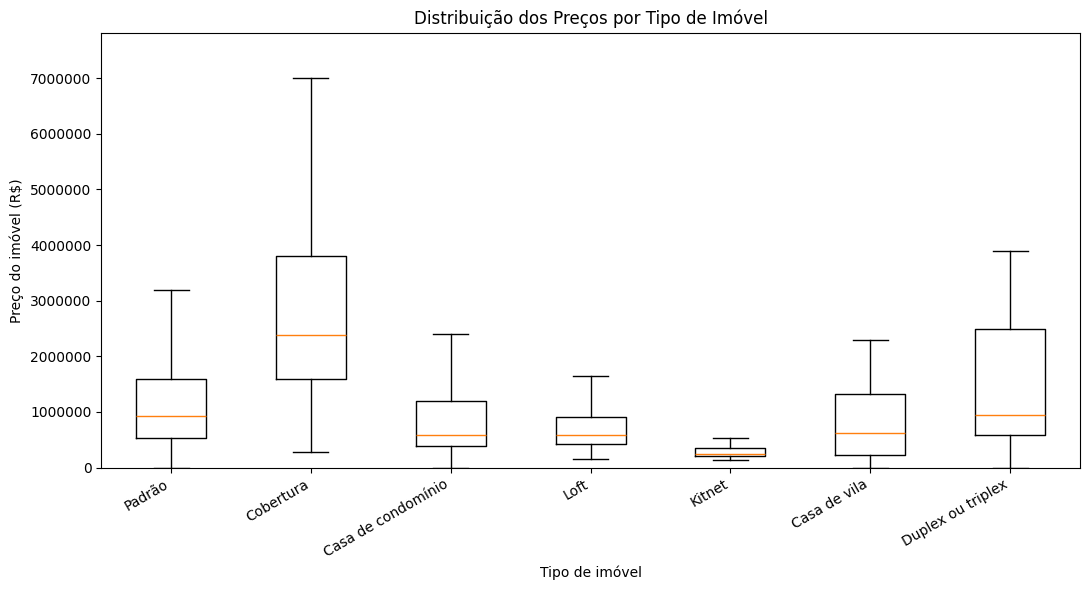

In [ ]:
# Ordem das categorias de tipo
ordem_tipos = [
    'Padrão',
    'Cobertura',
    'Casa de condomínio',
    'Loft',
    'Kitnet',
    'Casa de vila',
    'Duplex ou triplex'
]

# Organizar os preços por tipo
dados_tipos = [
    df.loc[df['Tipo'] == tipo, 'price']
    for tipo in ordem_tipos
]

# Limite visual pelo percentil 99 do preço
limite_preco = df['price'].quantile(0.99)

# Criar o boxplot
plt.figure(figsize=(11, 6))

plt.boxplot(
    dados_tipos,
    tick_labels=ordem_tipos,
    showfliers=False
)

plt.ylim(0, limite_preco)

plt.title('Distribuição dos Preços por Tipo de Imóvel')
plt.xlabel('Tipo de imóvel')
plt.ylabel('Preço do imóvel (R$)')

plt.xticks(rotation=30, ha='right')
plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()

### 8.8.1. Conclusões sobre a relação entre preço e tipo do imóvel

A análise demonstra que o **tipo do imóvel** está relacionado ao seu preço. As **Coberturas** apresentam a maior mediana e ampla dispersão dos valores, indicando preços geralmente superiores e grande diversidade dentro dessa categoria. As **Kitnets**, por outro lado, apresentam os menores preços e uma distribuição mais concentrada.

Os imóveis classificados como **Padrão**, **Casa de condomínio**, **Loft** e **Casa de vila** apresentam valores intermediários, com diferenças em suas medianas e dispersões. A categoria **Duplex ou triplex** também apresenta grande variação de preços, mas seus resultados devem ser interpretados com cautela devido à pequena quantidade de registros.

Portanto, a variável **Tipo** apresenta relevância para o futuro modelo de predição. Entretanto, categorias com poucos registros poderão exigir agrupamento ou tratamento específico antes da modelagem, evitando que resultados pouco representativos prejudiquem o aprendizado do modelo.

### 8.9. Relação entre preço e localização

Nesta etapa, será analisada a relação entre o **preço dos imóveis** e sua **localização**. Como a variável **location** apresenta 941 categorias distintas, a análise será concentrada nas localizações com maior quantidade de anúncios, evitando visualizações excessivamente extensas e pouco representativas.

A comparação permitirá identificar diferenças na mediana e na dispersão dos preços entre as principais localizações da base. Essa análise contribuirá para avaliar a influência da localização sobre o valor dos imóveis e sua relevância para o futuro modelo de predição.

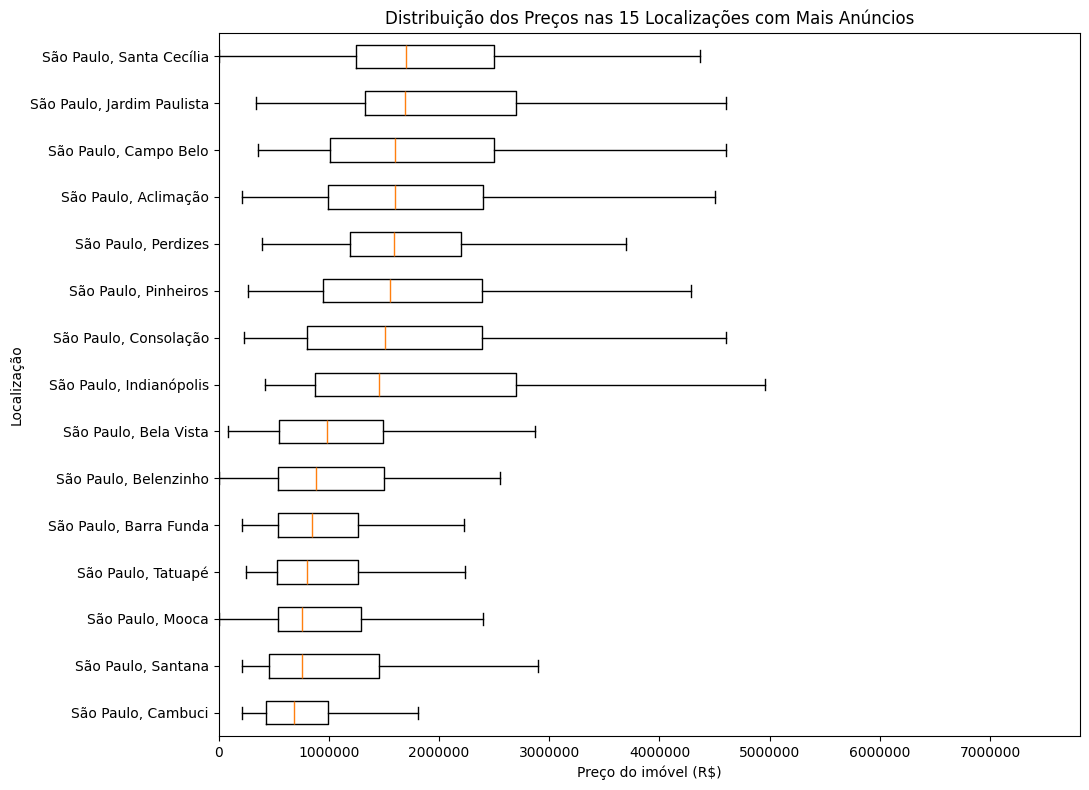

In [ ]:
# Selecionar as 15 localizações com maior quantidade de anúncios
principais_localizacoes = df['location'].value_counts().head(15).index

# Filtrar os registros dessas localizações
dados_localizacoes = df[
    df['location'].isin(principais_localizacoes)
]

# Organizar as localizações pela mediana dos preços
ordem_localizacoes = (
    dados_localizacoes
    .groupby('location')['price']
    .median()
    .sort_values()
    .index
)

# Organizar os preços por localização
precos_localizacoes = [
    dados_localizacoes.loc[
        dados_localizacoes['location'] == localizacao,
        'price'
    ]
    for localizacao in ordem_localizacoes
]

# Limite visual pelo percentil 99 do preço
limite_preco = df['price'].quantile(0.99)

# Criar o boxplot horizontal
plt.figure(figsize=(11, 8))

plt.boxplot(
    precos_localizacoes,
    tick_labels=ordem_localizacoes,
    showfliers=False,
    vert=False
)

plt.xlim(0, limite_preco)

plt.title('Distribuição dos Preços nas 15 Localizações com Mais Anúncios')
plt.xlabel('Preço do imóvel (R$)')
plt.ylabel('Localização')

plt.ticklabel_format(style='plain', axis='x')

plt.tight_layout()
plt.show()

#### 8.9.1. Conclusões sobre a relação entre preço e localização

A análise das 15 localizações com maior quantidade de anúncios demonstra diferenças relevantes na distribuição dos preços. Localizações como **Santa Cecília, Jardim Paulista, Campo Belo, Aclimação, Perdizes e Pinheiros** apresentam preços medianos mais elevados. Por outro lado, **Cambuci, Santana, Mooca e Tatuapé** apresentam menores medianas entre as regiões analisadas.

Também foram observadas diferenças na dispersão dos preços. Algumas localizações, como **Indianópolis, Jardim Paulista, Campo Belo e Santa Cecília**, apresentam maior amplitude de valores, indicando a presença de imóveis com características e padrões de preço variados.

Os resultados confirmam que a **localização** possui grande relevância para o futuro modelo de predição. Entretanto, esta análise considera apenas as 15 localizações com maior quantidade de anúncios. As demais categorias, especialmente aquelas com poucos registros, deverão ser avaliadas durante o tratamento dos dados para evitar dificuldades na preparação e no aprendizado do modelo.

### 8.10. Relação entre preço e valor do IPTU

Nesta etapa, será analisada a relação entre o **preço dos imóveis** e o **valor do IPTU**. O objetivo é verificar se imóveis que apresentam valores mais elevados de IPTU também tendem a possuir maiores preços de venda.

A análise será realizada por meio de um gráfico de dispersão e do cálculo da correlação entre as variáveis. Considerando a existência de valores extremos e possíveis inconsistências previamente identificadas na variável **IPTU**, serão utilizados limites visuais baseados no percentil 99 para facilitar a interpretação dos resultados, preservando os dados originais da base.

Essa análise contribui para avaliar o potencial da variável **IPTU** como atributo explicativo do preço dos imóveis, além de verificar se existe associação relevante entre os custos tributários do imóvel e seu valor de mercado.

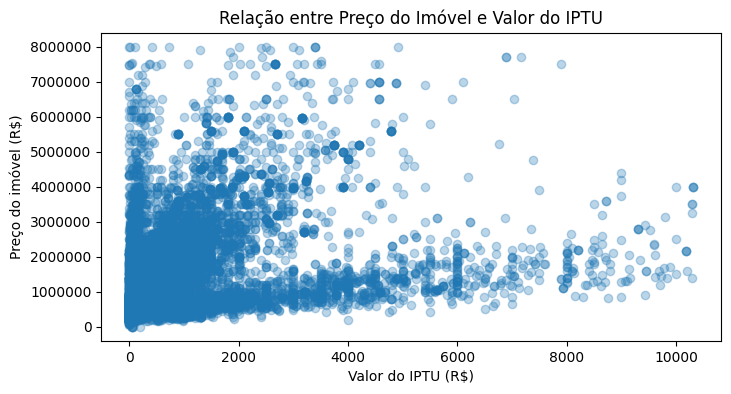

Correlação entre preço e IPTU: 0.3202


In [ ]:
# Selecionar registros válidos para a análise
dados_iptu = df[
    (df['price'] > 0) &
    (df['IPTU'].notna()) &
    (df['IPTU'] > 0)
].copy()

# Definir limites pelo percentil 99
limite_preco = dados_iptu['price'].quantile(0.99)
limite_iptu = dados_iptu['IPTU'].quantile(0.99)

# Selecionar dados apenas para visualização
dados_iptu_visualizacao = dados_iptu[
    (dados_iptu['price'] <= limite_preco) &
    (dados_iptu['IPTU'] <= limite_iptu)
]

# Gráfico de dispersão
plt.figure(figsize=(8, 4))

plt.scatter(
    dados_iptu_visualizacao['IPTU'],
    dados_iptu_visualizacao['price'],
    alpha=0.3
)

plt.title('Relação entre Preço do Imóvel e Valor do IPTU')
plt.xlabel('Valor do IPTU (R$)')
plt.ylabel('Preço do imóvel (R$)')

plt.ticklabel_format(style='plain', axis='both')

plt.show()

# Correlação entre preço e IPTU
correlacao_preco_iptu = (
    dados_iptu_visualizacao['price']
    .corr(dados_iptu_visualizacao['IPTU'])
)

print(
    f'Correlação entre preço e IPTU: '
    f'{correlacao_preco_iptu:.4f}'
)

#### 8.10.1. Conclusões sobre a relação entre preço e valor do IPTU

O gráfico de dispersão demonstra uma tendência positiva entre o **valor do IPTU** e o **preço dos imóveis**, indicando que imóveis com IPTUs mais elevados tendem, em média, a apresentar maiores preços de venda.

Entretanto, a dispersão dos registros é relativamente alta, especialmente entre os imóveis com IPTU mais baixo, evidenciando que imóveis com valores semelhantes de IPTU podem possuir preços bastante diferentes. Essa variação indica que o IPTU não explica o preço isoladamente, sendo influenciado por fatores como área útil, localização, padrão construtivo e características do imóvel.

A correlação calculada foi de **0,3202**, indicando uma relação positiva de intensidade moderada para fraca entre as variáveis. Esse resultado sugere que o IPTU possui alguma capacidade de representar diferenças de valor entre os imóveis, mas apresenta menor influência quando comparado a outras variáveis já analisadas, como **Condomínio** e **Área útil**.

Portanto, a variável **IPTU** poderá contribuir para o futuro modelo de predição, mas sua utilização deverá ocorrer em conjunto com outras características mais fortemente relacionadas ao preço dos imóveis.


#### 8.11. Correlação entre preço e variáveis binárias

Nesta etapa, será analisada a relação entre o **preço dos imóveis** e as principais **variáveis binárias** presentes na base de dados. Essas variáveis indicam a presença ou ausência de determinadas características dos imóveis e condomínios, sendo representadas pelos valores **0 (não possui)** e **1 (possui)**.

A análise será realizada por meio de uma matriz de correlação, permitindo identificar quais características apresentam maior associação com os preços dos imóveis. Embora a correlação não indique causalidade, ela fornece evidências sobre quais atributos podem ter maior potencial de contribuição para o futuro modelo de predição.


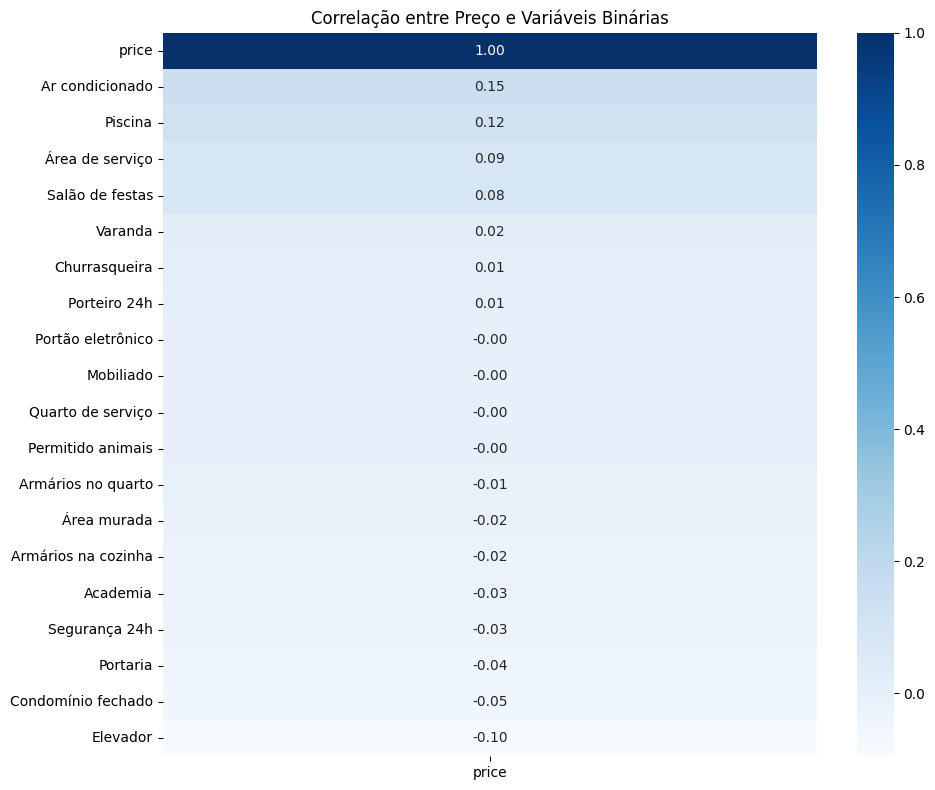

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

variaveis_binarias = [
    'Academia',
    'Elevador',
    'Permitido animais',
    'Piscina',
    'Portaria',
    'Salão de festas',
    'Condomínio fechado',
    'Segurança 24h',
    'Portão eletrônico',
    'Área murada',
    'Área de serviço',
    'Armários na cozinha',
    'Armários no quarto',
    'Churrasqueira',
    'Mobiliado',
    'Quarto de serviço',
    'Ar condicionado',
    'Porteiro 24h',
    'Varanda'
]

dados_corr = df[['price'] + variaveis_binarias]

matriz_corr = dados_corr.corr()

plt.figure(figsize=(10,8))

sns.heatmap(
    matriz_corr[['price']]
        .sort_values(by='price', ascending=False),
    annot=True,
    cmap='Blues',
    fmt='.2f'
)

plt.title('Correlação entre Preço e Variáveis Binárias')

plt.tight_layout()
plt.show()

#### 8.11.1. Conclusões sobre a correlação entre preço e variáveis binárias

A matriz de correlação demonstra que nenhuma das variáveis binárias apresenta associação forte com a variável-alvo **price**. As maiores correlações positivas foram observadas para **Ar condicionado (0,15)**, **Piscina (0,12)**, **Área de serviço (0,09)** e **Salão de festas (0,08)**, indicando relações positivas, porém de baixa intensidade.

A maioria das características analisadas apresentou correlações muito próximas de zero, sugerindo que sua presença ou ausência, isoladamente, possui capacidade limitada para explicar a variação dos preços dos imóveis. Esse resultado não significa que essas características sejam irrelevantes, mas sim que sua influência tende a ocorrer em conjunto com outros fatores, como área útil, localização, quantidade de quartos, banheiros e padrão do imóvel.

Os resultados indicam que as variáveis binárias poderão contribuir para o futuro modelo de Machine Learning, porém devem ser utilizadas como variáveis complementares, não representando os principais fatores de explicação dos preços observados na base de dados.

### 8.12. Matriz Geral de Correlação das Principais Variáveis

Nesta etapa, será analisada a correlação entre as principais variáveis quantitativas selecionadas para o projeto. O objetivo é identificar quais características apresentam maior associação com o preço dos imóveis e verificar a existência de relações relevantes entre as próprias variáveis explicativas.

A matriz de correlação permite visualizar simultaneamente a intensidade e a direção das relações lineares entre as variáveis, auxiliando na compreensão da estrutura dos dados e na futura seleção dos atributos que poderão ser utilizados nos modelos de Machine Learning.

Considerando que análises anteriores identificaram a presença de valores extremos nas variáveis **Área útil** e **price**, a matriz foi construída utilizando os mesmos limites visuais empregados na análise da relação entre preço e área útil, restringindo a visualização aos registros situados até o percentil 99 dessas variáveis. Essa estratégia tem como objetivo reduzir a influência dos outliers sobre os coeficientes de correlação, permitindo uma representação mais fiel dos padrões observados na maior parte da base de dados.

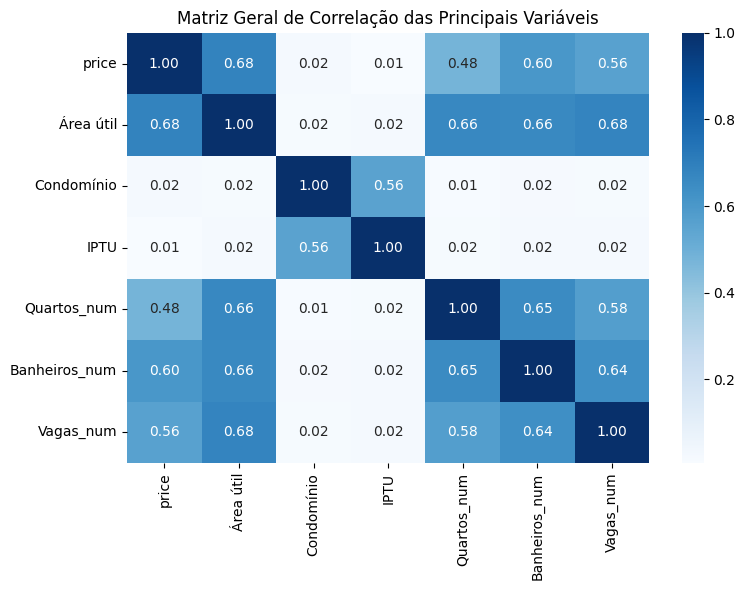

In [ ]:
ceimport seaborn as sns
import matplotlib.pyplot as plt

# Criar cópia para análise
dados_corr = df.copy()

# Conversões temporárias
dados_corr['Quartos_num'] = (
    dados_corr['Quartos']
    .replace('5 ou mais', '5')
    .astype(float)
)

dados_corr['Banheiros_num'] = (
    dados_corr['Banheiros']
    .replace('5 ou mais', '5')
    .astype(float)
)

dados_corr['Vagas_num'] = (
    dados_corr['Vagas na garagem']
    .replace('5 ou mais', '5')
    .astype(float)
)

# Limites visuais (mesma lógica utilizada anteriormente)
limite_preco = dados_corr['price'].quantile(0.99)
limite_area = dados_corr['Área útil'].quantile(0.99)

# Base filtrada apenas para análise
dados_corr_filtrado = dados_corr[
    (dados_corr['price'] > 0) &
    (dados_corr['price'] <= limite_preco) &
    (dados_corr['Área útil'] > 0) &
    (dados_corr['Área útil'] <= limite_area)
]

# Variáveis da matriz
variaveis = [
    'price',
    'Área útil',
    'Condomínio',
    'IPTU',
    'Quartos_num',
    'Banheiros_num',
    'Vagas_num'
]

# Matriz de correlação
matriz_corr = dados_corr_filtrado[variaveis].corr()

# Heatmap
plt.figure(figsize=(8,6))

sns.heatmap(
    matriz_corr,
    annot=True,
    cmap='Blues',
    fmt='.2f'
)

plt.title('Matriz Geral de Correlação das Principais Variáveis')

plt.tight_layout()
plt.show()

#### 8.12.1. Conclusões sobre a matriz geral de correlação

A matriz de correlação permitiu analisar simultaneamente as relações entre as principais variáveis quantitativas selecionadas para o projeto. Para reduzir a influência dos valores extremos identificados anteriormente, especialmente nas variáveis **Área útil** e **price**, a análise foi realizada utilizando os mesmos limites visuais adotados no item 8.1, considerando apenas os registros situados até o percentil 99 dessas variáveis.

Os resultados demonstram que a **Área útil** apresenta a maior associação com a variável-alvo **price**, com correlação de **0,68**, indicando uma relação positiva de intensidade moderada a forte. Esse resultado confirma as análises anteriores e evidencia que imóveis com maior área tendem a apresentar preços mais elevados.

Também foram observadas correlações relevantes entre o preço e as variáveis **Banheiros (0,60)**, **Vagas na garagem (0,56)** e **Quartos (0,48)**. Esses resultados indicam que imóveis maiores e com melhor infraestrutura tendem a possuir maior valor de mercado.

Entre as variáveis explicativas, destacam-se as correlações positivas entre **Área útil**, **Quartos**, **Banheiros** e **Vagas na garagem**, sugerindo que essas características costumam ocorrer conjuntamente nos imóveis analisados. Esse comportamento é coerente com o mercado imobiliário, uma vez que imóveis de maior porte normalmente oferecem mais cômodos e maior estrutura.

Por outro lado, as variáveis **Condomínio** e **IPTU** apresentaram correlações reduzidas com o preço nesta análise, indicando menor capacidade de explicar isoladamente as variações observadas

## ***9. Principais Conclusões da Análise Exploratória***

A análise exploratória permitiu compreender a estrutura, a qualidade e os principais padrões presentes na base de dados utilizada neste projeto. A base é composta por 23.433 registros e 38 variáveis relacionadas às características físicas dos imóveis, localização, valores financeiros e infraestrutura disponível.

Durante a etapa de investigação foram identificados valores ausentes, registros duplicados e valores extremos em algumas variáveis, especialmente em **price**, **Área útil**, **Condomínio** e **IPTU**. Essas situações não comprometeram a análise exploratória, mas deverão ser tratadas posteriormente para evitar impactos negativos no treinamento dos modelos de Machine Learning.

As análises individuais demonstraram que variáveis como **Área útil**, **Quartos**, **Banheiros**, **Vagas na garagem**, **Condomínio**, **IPTU**, **Zona** e **Location** apresentam características potencialmente relevantes para a predição dos preços dos imóveis. Também foi constatado que algumas variáveis possuem baixa utilidade para o projeto, seja pela elevada quantidade de valores ausentes, seja por representarem informações textuais fora do escopo desta pesquisa.

As análises relacionais permitiram identificar que a **Área útil** representa a característica com maior associação ao preço dos imóveis, seguida pelas variáveis **Banheiros**, **Vagas na garagem** e **Quartos**. Os resultados demonstraram que imóveis maiores e com melhor infraestrutura tendem a apresentar maiores valores de mercado.

A análise das variáveis binárias indicou que características como piscina, ar-condicionado, varanda e salão de festas apresentam associação positiva com os preços, porém de baixa intensidade quando avaliadas individualmente. Esse comportamento sugere que essas informações podem contribuir para o modelo de predição, mas provavelmente atuarão como variáveis complementares em conjunto com características mais relevantes.

A matriz geral de correlação confirmou que as variáveis relacionadas ao tamanho e à estrutura dos imóveis apresentam as associações mais significativas com a variável-alvo **price**. Também foi observada correlação entre algumas variáveis explicativas, comportamento esperado em bases imobiliárias, uma vez que imóveis maiores normalmente concentram mais quartos, banheiros e vagas de garagem.

De forma geral, os resultados obtidos nesta etapa demonstram que a base de dados apresenta potencial adequado para o desenvolvimento de modelos de predição de preços. Entretanto, antes da etapa de modelagem, será necessário realizar procedimentos de tratamento dos dados, incluindo remoção de registros duplicados, tratamento de valores ausentes, investigação de valores extremos, adequação dos tipos de dados e preparação das variáveis para utilização nos algoritmos de Machine Learning.

Com a conclusão desta análise exploratória, encontram-se estabelecidas as condições necessárias para iniciar a próxima fase do projeto, dedicada ao tratamento e à preparação dos dados para construção dos modelos preditivos.

### 9.1. Encaminhamento para a etapa de tratamento dos dados

A análise exploratória permitiu identificar diversos aspectos que deverão ser considerados na próxima fase do projeto, dedicada ao tratamento e à preparação dos dados para utilização nos modelos de Machine Learning.

Entre os principais pontos identificados destacam-se:

- Remoção dos registros duplicados identificados durante a análise exploratória;
- Tratamento dos valores ausentes presentes nas variáveis **oldPrice**, **Detalhes do imóvel**, **Detalhes do condomínio**, **IPTU**, **Condomínio** e **Banheiros**;
- Investigação e tratamento dos valores extremos observados nas variáveis **price**, **Área útil**, **Condomínio** e **IPTU**;
- Conversão das variáveis **Quartos**, **Banheiros** e **Vagas na garagem** para formato numérico;
- Avaliação da permanência ou exclusão das variáveis consideradas pouco relevantes para o projeto;
- Tratamento das variáveis categóricas e binárias para utilização nos algoritmos de Machine Learning;
- Definição das variáveis que serão utilizadas como atributos de entrada do modelo preditivo.

Essas atividades serão realizadas no próximo notebook do projeto, que terá como objetivo preparar a base de dados para as etapas de treinamento, validação e avaliação dos modelos de Machine Learning.

In [ ]:
!jupyter nbconvert \
    --to html \
    --no-input \
    "/content/drive/MyDrive/Colab Notebooks/PROJETO IV- UNIVESP/PRECO_IMOVEIS_SP.ipynb"



[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/PROJETO IV- UNIVESP/PRECO_IMOVEIS_SP.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 26 image(s).
[NbConvertApp] Writing 2150154 bytes to /content/drive/MyDrive/Colab Notebooks/PROJETO IV- UNIVESP/PRECO_IMOVEIS_SP.html
